# 03a - Supervised EDA and Modeling

## Purpose

This notebook covers the supervised branch of the project: exploratory analysis of U.S. counties using healthcare-resource, HPSA, and geographic-context features, followed by model training, comparison, interpretation, and robustness checks.

## Goals

Our primary question is: **how well can county-level healthcare access characteristics – such as primary-care provider supply, healthcare infrastructure, provider-shortage designations, and rurality – predict the percentage of adults receiving a routine checkup within the past year?**

- Describe the target and the primary features (distribution, missingness, skew, redundancy, nonlinearity).
- Compare a median baseline against three model families – Elastic Net, SVR, and Gradient Boosting – using MAE as the primary metric (RMSE and R² secondary).
- Interpret the selected model with permutation importance, feature-group ablation, partial dependence, and SHAP.
- Test whether conclusions hold under **alternative feature specifications** (HPSA count/score, detailed RUCC, raw density, SVI) and under **state-grouped cross-validation**.
- Identify the kinds of counties where the selected model fails.

## Data Sources

From `data/processed/` and `data/reference/` we load `master_county_analytical.csv` and `feature_manifest.csv` (produced in notebook 02).

## 1. Imports and Paths

In [66]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, enet_path
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.model_selection import (
    KFold, GroupKFold, GridSearchCV, cross_validate, cross_val_predict, train_test_split,
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

In [5]:
# main paths
PROJECT_ROOT = Path("..")
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
REFERENCE_DIR = DATA_DIR / "reference"
RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR.mkdir(exist_ok=True)

# supervised learning directory
SUP_RESULTS_DIR = RESULTS_DIR / "supervised"
SUP_FIG_DIR = FIG_DIR / "supervised"
SUP_TABLE_DIR = SUP_RESULTS_DIR 
for d in (SUP_RESULTS_DIR, SUP_FIG_DIR, SUP_TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

# configurations
RANDOM_STATE = 42
N_SPLITS = 5

TARGET = "routine_checkup_pct"
GROUP_COL = "state_abbr"
ID_COLS = ["fips", "state_abbr", "county_name_places", "places_target_year"]

# plot defaults
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

# fixed colors so each model / CV scheme keeps the same color in every plot
MODEL_ORDER = ["Dummy", "Elastic Net", "SVR", "Gradient Boosting"]
MODEL_COLORS = {"Dummy": "#9a9a9a", "Elastic Net": "#2a78d6", "SVR": "#eb6834", "Gradient Boosting": "#1baf7a"}
CV_COLORS = {"random": "#2a78d6", "state_grouped": "#eb6834"}


def savefig(name):
    plt.savefig(SUP_FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

## 2. Load Clean and Merged Data

### 2.1 Load data and feature manifest

In [6]:
shared_analytical = pd.read_csv(
    PROCESSED_DIR / "master_county_analytical.csv",
    dtype={"fips": "string"},
    low_memory=False,
)

feature_manifest = pd.read_csv(REFERENCE_DIR / "feature_manifest.csv")

print(shared_analytical.shape)
feature_manifest["analysis"].value_counts()

(3144, 50)


analysis
unsupervised                           27
supervised_svi_sensitivity             16
reference                              12
supervised                             11
unsupervised_sensitivity                6
supervised_sensitivity                  5
unsupervised_hpsa_score_sensitivity     3
Name: count, dtype: int64

### 2.2 Manifest Variable Setup 

The manifest's `supervised_sensitivity` group also lists `pers_noins_lt65_pct_21` (percent uninsured under 65, 2021). It is excluded from this analysis: it covers only adults under 65, comes from a different year than the outcome, and largely duplicates SVI's `EP_UNINSUR`, so uninsurance is represented through the SVI sensitivity specification instead.

In [7]:
def manifest_vars(analysis, role="predictor"):
    # list of variables for a given manifest analysis group
    rows = feature_manifest[
        (feature_manifest["analysis"] == analysis) & (feature_manifest["role"] == role)
    ]
    return rows["variable"].tolist()


PRIMARY_FEATURES = manifest_vars("supervised")
# the uninsured rate is excluded (see note above); uninsurance enters through SVI's EP_UNINSUR instead
EXCLUDED_FEATURES = ["pers_noins_lt65_pct_21"]
SENSITIVITY_FEATURES = [f for f in manifest_vars("supervised_sensitivity") if f not in EXCLUDED_FEATURES]
SVI_FEATURES = manifest_vars("supervised_svi_sensitivity")


def swap(features, old, new):
    # replace one feature with its alternative representation but still keeping the order
    assert old in features, old
    return [new if f == old else f for f in features]


# each sensitivity spec differs from the primary specification in exactly one place
FEATURE_SPECS = {
    "primary":        PRIMARY_FEATURES,
    "hpsa_count_alt": swap(PRIMARY_FEATURES, "pc_hpsa_any", "pc_hpsa_count"),
    "hpsa_score_alt": PRIMARY_FEATURES + ["pc_hpsa_max_score"],
    "rurality_alt":   swap(PRIMARY_FEATURES, "rucc_metro_status", "rural_urban_contnm_23"),
    "density_alt":    swap(PRIMARY_FEATURES, "log_population_density", "popn_densty_per_squr_mi_20"),
    "svi":            PRIMARY_FEATURES + SVI_FEATURES,
}

# feature types for preprocessing
# detailed RUCC is an ordered category, but the distance between codes is not meaningful,
# so it is one-hot encoded rather than passed through the numeric pipeline
CATEGORICAL_FEATURES = ["rucc_metro_status", "rural_urban_contnm_23"]
BINARY_FEATURES = ["pc_hpsa_any"]
# HPSA score is missing when a county has no qualifying designation (structural, not random)
HPSA_SCORE_FEATURES = ["pc_hpsa_max_score"]


def split_feature_types(features):
    # split a feature list into numeric, binary, categorical, and hpsa score but still preserving order
    cat = [f for f in features if f in CATEGORICAL_FEATURES]
    binary = [f for f in features if f in BINARY_FEATURES]
    score = [f for f in features if f in HPSA_SCORE_FEATURES]
    num = [f for f in features if f not in cat + binary + score]
    return num, binary, cat, score

# display the number of features in each spec
pd.DataFrame(
    [{"spec": k, "n_features": len(v),
      "differs_from_primary": ", ".join(sorted(set(v) ^ set(PRIMARY_FEATURES))) or "-"}
     for k, v in FEATURE_SPECS.items()]
)

,spec,n_features,differs_from_primary
0,primary,10,-
1,hpsa_count_alt,10,"pc_hpsa_any, pc_hpsa_count"
2,hpsa_score_alt,11,pc_hpsa_max_score
3,rurality_alt,10,"rucc_metro_status, rural_urban_contnm_23"
4,density_alt,10,"log_population_density, popn_densty_per_squr_m..."
5,svi,26,"EP_AGE17, EP_AGE65, EP_CROWD, EP_DISABL, EP_GR..."


### 2.3 Create Feature Groups

In [8]:
# feature groups as suggested in project proposal
FEATURE_GROUPS = {
    "provider_supply": [
        "primary_care_physicians_per_100k",
        "nurse_practitioners_per_100k",
        "physician_assistants_per_100k",
    ],
    "healthcare_infrastructure": [
        "hospitals_per_100k",
        "hospital_beds_per_1000",
        "fqhcs_per_100k",
        "rural_health_clinics_per_100k",
    ],
    "provider_shortage": ["pc_hpsa_any", "pc_hpsa_count", "pc_hpsa_max_score"],
    "geographic_access_context": [
        "log_population_density",
        "rucc_metro_status",
        "rural_urban_contnm_23",
        "popn_densty_per_squr_mi_20",
    ],
    "svi_indicators": SVI_FEATURES,
}

# the groups restricted to the primary specification (used for ablation in Section 6)
PRIMARY_GROUPS = {
    g: [f for f in feats if f in PRIMARY_FEATURES]
    for g, feats in FEATURE_GROUPS.items()
    if any(f in PRIMARY_FEATURES for f in feats)
}
PRIMARY_GROUPS

{'provider_supply': ['primary_care_physicians_per_100k',
  'nurse_practitioners_per_100k',
  'physician_assistants_per_100k'],
 'healthcare_infrastructure': ['hospitals_per_100k',
  'hospital_beds_per_1000',
  'fqhcs_per_100k',
  'rural_health_clinics_per_100k'],
 'provider_shortage': ['pc_hpsa_any'],
 'geographic_access_context': ['log_population_density', 'rucc_metro_status']}

### 2.4 Modeling Dataframe Setup

In [9]:
ALL_MODEL_FEATURES = list(dict.fromkeys(sum(FEATURE_SPECS.values(), [])))

df = shared_analytical[ID_COLS + [TARGET] + ALL_MODEL_FEATURES].copy()

y = df[TARGET]
groups = df[GROUP_COL]

print(f"Modeling frame: {df.shape[0]:,} counties x {len(ALL_MODEL_FEATURES)} candidate features")
print(f"States/DC (CV groups): {groups.nunique()}")
df.head()

Modeling frame: 3,144 counties x 30 candidate features
States/DC (CV groups): 51


,fips,state_abbr,county_name_places,places_target_year,routine_checkup_pct,primary_care_physicians_per_100k,nurse_practitioners_per_100k,physician_assistants_per_100k,hospitals_per_100k,hospital_beds_per_1000,fqhcs_per_100k,rural_health_clinics_per_100k,log_population_density,pc_hpsa_any,rucc_metro_status,pc_hpsa_count,pc_hpsa_max_score,rural_urban_contnm_23,popn_densty_per_squr_mi_20,EP_POV150,EP_UNEMP,EP_HBURD,EP_NOHSDP,EP_UNINSUR,EP_AGE65,EP_AGE17,EP_DISABL,EP_SNGPNT,EP_LIMENG,EP_MINRTY,EP_MUNIT,EP_MOBILE,EP_CROWD,EP_NOVEH,EP_GROUPQ
0,06045,CA,Mendocino,2022,68.6,80.193355,83.534745,32.300101,3.341390,1.314280,15.593152,7.796576,3.299534,1,Nonmetro,8,17.0,4.0,26.1,25.4,9.1,33.4,13.2,9.2,23.3,21.1,18.7,7.0,4.4,37.2,4.4,9.9,4.9,8.0,2.7
1,02063,AK,Chugach,2022,62.2,145.475706,14.547571,29.095141,0.000000,0.000000,NaN,NaN,0.587787,1,Nonmetro,1,13.0,9.0,0.8,10.6,8.8,20.1,5.5,14.7,13.2,21.7,15.9,5.4,1.7,29.5,10.1,15.6,5.6,5.7,3.6
2,04007,AZ,Gila,2022,68.8,50.072327,53.781388,38.945143,3.709061,1.131264,3.709061,11.127184,2.501436,1,Nonmetro,5,21.0,4.0,11.2,30.6,6.9,24.2,12.9,9.8,29.6,19.4,21.2,3.6,0.6,38.8,1.2,19.8,4.4,6.9,2.3
3,05087,AR,Madison,2022,74.5,22.875443,51.469747,0.000000,0.000000,0.000000,5.718861,0.000000,3.034953,1,Metro,1,12.0,2.0,19.8,30.1,4.8,16.5,15.0,10.4,19.5,23.4,19.8,6.3,0.0,24.2,1.1,18.2,3.5,3.2,0.5
4,05067,AR,Jackson,2022,76.7,30.076997,102.261790,12.030799,6.015399,2.045236,12.030799,0.000000,3.310543,0,Nonmetro,0,NaN,6.0,26.4,36.0,10.9,22.5,13.7,8.4,17.8,19.5,23.2,7.7,0.1,24.1,0.9,9.6,0.4,8.0,13.7


## 3. Train/Test Split

In [10]:
X_all = df[ALL_MODEL_FEATURES].copy()

# stratify on target quintiles so both the train and test set span the full range of the target
y_bins = pd.qcut(y, q=5, labels=False)

# get indexes for rows that are in train vs test
idx_train, idx_test = train_test_split(
    df.index,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_bins,
)

# use the indexes to grab the train/test set
X_train, X_test = X_all.loc[idx_train], X_all.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# train/test set for the grouped analysis
groups_train, groups_test = groups.loc[idx_train], groups.loc[idx_test]

print(f"Train: {len(X_train):,} counties | Test: {len(X_test):,} counties")
print(f"States represented - train: {groups_train.nunique()}, test: {groups_test.nunique()}")

pd.DataFrame({
    "train": y_train.describe(),
    "test": y_test.describe(),
}).round(2)

Train: 2,515 counties | Test: 629 counties
States represented - train: 51, test: 49


,train,test
count,2515.00,629.00
mean,73.81,73.86
std,3.58,3.56
min,59.30,62.20
25%,71.60,71.70
50%,74.40,74.40
75%,76.30,76.50
max,82.70,83.10


### 3.1 Missing AHRF Data 

In [11]:
# where did the structurally-missing AHRF counties land?
ahrf_rate_check = "primary_care_physicians_per_100k"
missing_ahrf = df.loc[df[ahrf_rate_check].isna(), ["fips", "state_abbr", "county_name_places"]].copy()
missing_ahrf["split"] = np.where(missing_ahrf.index.isin(idx_train), "train", "test")
missing_ahrf

,fips,state_abbr,county_name_places,split
273,09130,CT,Lower Connecticut River Valley,test
282,09110,CT,Capitol,train
354,09150,CT,Northeastern Connecticut,train
401,09180,CT,Southeastern Connecticut,train
439,09140,CT,Naugatuck Valley,train
450,09120,CT,Greater Bridgeport,test
457,09170,CT,South Central Connecticut,train
462,09190,CT,Western Connecticut,train
465,09160,CT,Northwest Hills,train


## 4. Exploratory Data Analysis

All EDA below uses the 2,515 training counties. The questions follow the team's EDA plan:

| EDA question | Output |
|---|---|
| What does the target look like? | histogram/boxplot + summary (4.1) |
| Which features have missingness? | missingness table (4.2) |
| Which predictors are strongly related/redundant? | Spearman correlation matrix + VIF (4.3) |
| Which predictors are strongly skewed/outlier-prone? | distribution/skew summary (4.4) |
| Does utilization differ by metro status or HPSA designation? | boxplots (4.5) |
| Are relationships visibly nonlinear? | binned scatterplots vs target (4.6) |

In [12]:
# use train data for EDA
eda = df.loc[idx_train].copy()
eda_y = eda[TARGET]

### 4.1 Target Distribution

In [13]:
# basic descriptives
summary = eda_y.describe().to_frame("routine_checkup_pct").T

# add skew and IQR
summary["skew"] = eda_y.skew()
summary["IQR"] = eda_y.quantile(0.75) - eda_y.quantile(0.25)

display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max,skew,IQR
routine_checkup_pct,2515.0,73.81,3.58,59.3,71.6,74.4,76.3,82.7,-0.6,4.7


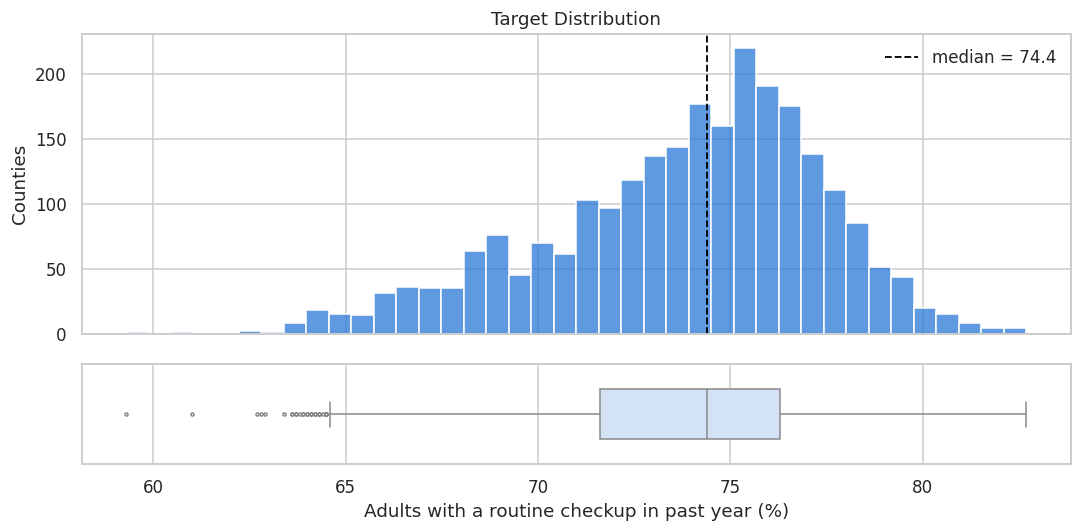

In [14]:
# histogram on top, horizontal boxplot below, sharing the x-axis
fig, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(10, 5), sharex=True,
                                      gridspec_kw={"height_ratios": [3, 1]})

# histogram
sns.histplot(x=eda_y, 
             bins=40, 
             ax=ax_hist, 
             color="#2a78d6", 
             edgecolor="white")

# add median line
ax_hist.axvline(eda_y.median(), 
                color="black", 
                lw=1.2, ls="--",
                label=f"median = {eda_y.median():.1f}")

ax_hist.set(ylabel="Counties", 
            title="Target Distribution")
ax_hist.legend(frameon=False)

# boxplot
sns.boxplot(x=eda_y, 
            ax=ax_box, 
            color="#cde2fb", 
            width=0.5, 
            fliersize=2)
ax_box.set(xlabel="Adults with a routine checkup in past year (%)")

plt.tight_layout()
savefig("eda_target_distribution")
plt.show()



How much of the target's variance sits *between* states? If a large share does, ordinary random CV (where counties from the same state appear in both training and validation folds) can be optimistic, and state-grouped CV becomes an important robustness check.

In [15]:
# calculate eta sq 
state_means = eda_y.groupby(eda[GROUP_COL]).transform("mean")
total_var = ((eda_y - eda_y.mean()) ** 2).sum()
within_state_var = ((eda_y - state_means) ** 2).sum()
eta_sq = 1 - within_state_var / total_var
print(f"Share of target variance explained by state membership alone (eta^2): {eta_sq:.2f}")

Share of target variance explained by state membership alone (eta^2): 0.88


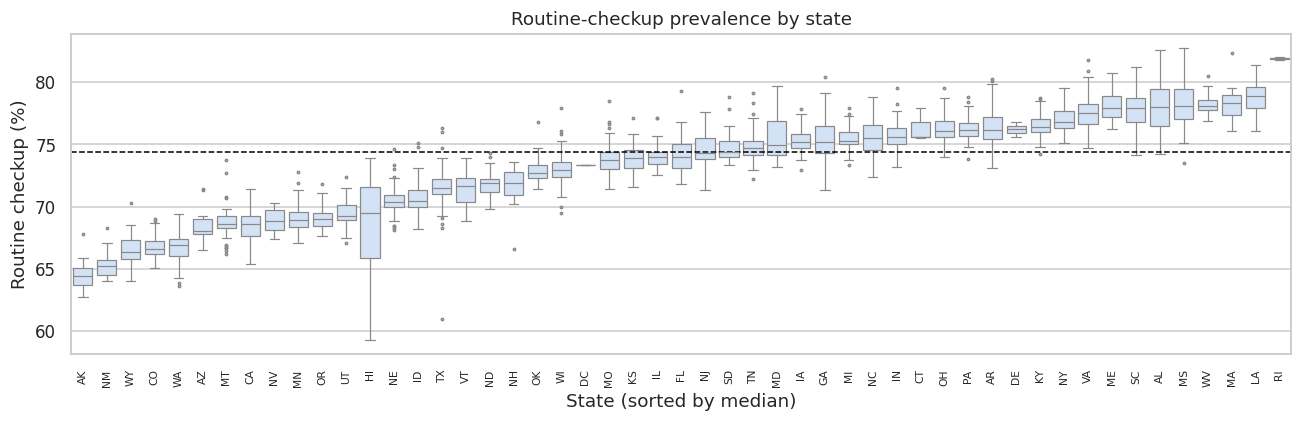

In [16]:
# order by median
order = eda.groupby(GROUP_COL)[TARGET].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 4))

# boxplot for each
sns.boxplot(data=eda, 
            x=GROUP_COL, y=TARGET, 
            order=order, ax=ax, 
            color="#cde2fb", fliersize=1.5, linewidth=0.8)

# add median line
ax.axhline(eda_y.median(), color="black", lw=1, ls="--")

ax.set(xlabel="State (sorted by median)", 
       ylabel="Routine checkup (%)",
       title="Routine-checkup prevalence by state")
ax.tick_params(axis="x", labelsize=7, rotation=90)

plt.tight_layout()
savefig("eda_target_by_state")
plt.show()

**Takeaways – target.**
- Routine-checkup prevalence is concentrated in a narrow band (IQR 71.6–76.3%, SD 3.6 pp) with a modest left tail (skew −0.6) of low-utilization counties down to ~59%. With an SD of 3.6 pp, the median baseline's MAE of ~2.8 pp is the bar every model has to beat.
- **State membership alone explains ~88% of the target's variance.** The within-state SD is only ~1.2 pp, compared with an overall SD of 3.6 pp. State medians range from the mid-60s to ~80+. This is consistent with PLACES being a model-based small-area estimate built on state-level BRFSS data.

### 4.2 Missingness

In [17]:
miss_rows = []

# primary, sensitivity, then svi
for spec_group, feats in [("primary", PRIMARY_FEATURES), ("sensitivity", SENSITIVITY_FEATURES), ("svi", SVI_FEATURES)]:
    # for each feature in the spec
    for f in feats:
        # count the number of missing rows
        n = eda[f].isna().sum()
        miss_rows.append({
            "feature": f, 
            "group": spec_group, 
            "n_missing": n, 
            "pct_missing": 100 * n / len(eda),
            "states_with_missing": ", ".join(sorted(eda.loc[eda[f].isna(), GROUP_COL].unique())),
        })


missingness = pd.DataFrame(miss_rows)

# show just the features with missing values and sort descending
missingness_nonzero = missingness[missingness["n_missing"] > 0].sort_values("n_missing", ascending=False)
display(missingness_nonzero.round(2))
print(f"{(missingness['n_missing'] == 0).sum()} of {len(missingness)} candidate features have no missing values in training.")

,feature,group,n_missing,pct_missing,states_with_missing
11,pc_hpsa_max_score,sensitivity,351,13.96,"AK, AL, AR, CA, CO, CT, FL, GA, HI, IA, ID, IL..."
5,fqhcs_per_100k,primary,8,0.32,"AK, CT"
6,rural_health_clinics_per_100k,primary,8,0.32,"AK, CT"
0,primary_care_physicians_per_100k,primary,7,0.28,CT
1,nurse_practitioners_per_100k,primary,7,0.28,CT
2,physician_assistants_per_100k,primary,7,0.28,CT
4,hospital_beds_per_1000,primary,7,0.28,CT
3,hospitals_per_100k,primary,7,0.28,CT
7,log_population_density,primary,7,0.28,CT
13,popn_densty_per_squr_mi_20,sensitivity,7,0.28,CT


20 of 30 candidate features have no missing values in training.


In [18]:
# check for missingness in HPSA max score - ordinary or structural
pd.crosstab(eda["pc_hpsa_any"], eda["pc_hpsa_max_score"].isna(),
            rownames=["pc_hpsa_any"], colnames=["score missing"])

score missing,False,True
pc_hpsa_any,,
0,0,351
1,2164,0


In [19]:
# which non-Connecticut couties are missing FQHC / RHC rates
eda.loc[eda["fqhcs_per_100k"].isna() & eda["primary_care_physicians_per_100k"].notna(),
        ["fips", "state_abbr", "county_name_places", "fqhcs_per_100k", "rural_health_clinics_per_100k"]]

,fips,state_abbr,county_name_places,fqhcs_per_100k,rural_health_clinics_per_100k
222,02275,AK,Wrangell,NaN,NaN


**Takeaways – missingness.**
- Primary-feature missingness is small (≤ 8 training counties, 0.3%) and structural. The 7 Connecticut planning regions in training are missing every AHRF-derived feature, and one Alaska borough (Wrangell) is also missing FQHC/RHC rates. These counties are handled by within-fold median imputation plus missing-indicator columns (Section 5.2) rather than being dropped.
- `pc_hpsa_max_score` is missing for 351 training counties (14%), and those are the same counties with `pc_hpsa_any = 0`. This confirms the missingness means "no qualifying designation", not ordinary missing data, so it gets a consistent fill instead of median imputation.

### 4.3 Correlation and Redundancy

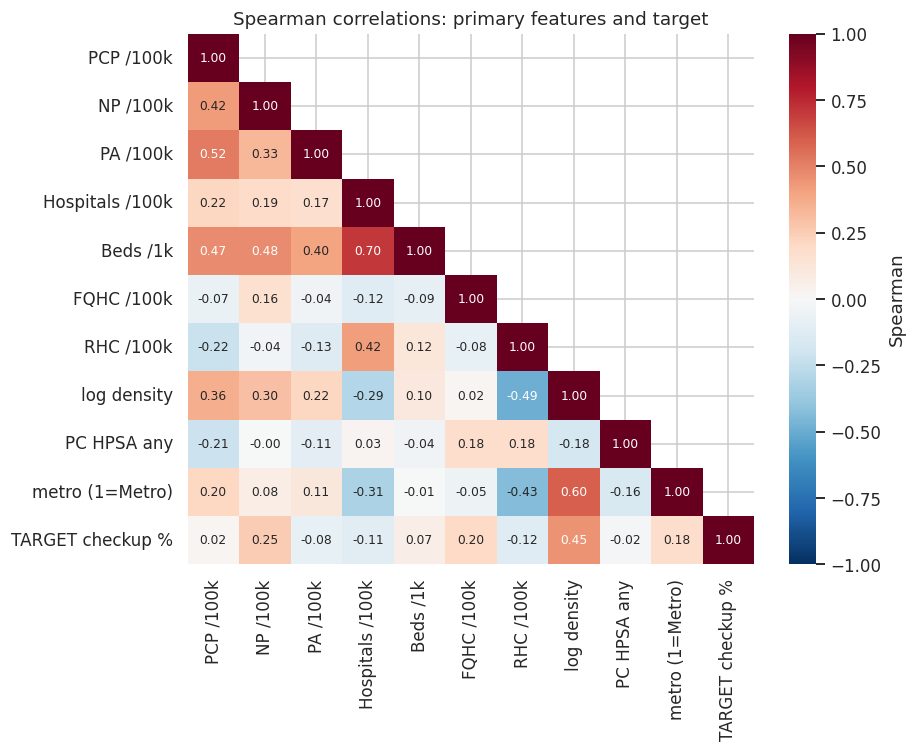

Feature pairs with |rho| >= 0.5:


,feature_a,feature_b,rho
27,hospitals_per_100k,hospital_beds_per_1000,0.70
50,log_population_density,metro (1=Metro),0.60
1,primary_care_physicians_per_100k,physician_assistants_per_100k,0.52


In [20]:
# Spearman is rank-based, so it is unaffected by the heavy right skew of the rate features

# select numeric features
corr_cols = [f for f in PRIMARY_FEATURES if f not in CATEGORICAL_FEATURES]
# add in the target
eda_corr = eda[corr_cols + [TARGET]].copy()
# turn rucc_metro_status into numeric
eda_corr.insert(len(corr_cols), "metro (1=Metro)", (eda["rucc_metro_status"] == "Metro").astype(int))
# calculate correlation matrix
spearman = eda_corr.corr(method="spearman")

# create shorter feature names for readability
short = {
    "primary_care_physicians_per_100k": "PCP /100k", "nurse_practitioners_per_100k": "NP /100k",
    "physician_assistants_per_100k": "PA /100k", "hospitals_per_100k": "Hospitals /100k",
    "hospital_beds_per_1000": "Beds /1k", "fqhcs_per_100k": "FQHC /100k",
    "rural_health_clinics_per_100k": "RHC /100k", "log_population_density": "log density",
    "pc_hpsa_any": "PC HPSA any", "routine_checkup_pct": "TARGET checkup %",
    "rucc_metro_status": "Metro status"
}
# hide the upper triangle
mask = np.triu(np.ones_like(spearman, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(spearman.rename(index=short, columns=short), 
            mask=mask, 
            annot=True, 
            fmt=".2f",
            cmap="RdBu_r", 
            center=0, vmin=-1, vmax=1, 
            annot_kws={"size": 8}, ax=ax,
            cbar_kws={"label": "Spearman"})
ax.set_title("Spearman correlations: primary features and target")
plt.tight_layout()
savefig("eda_spearman_primary")
plt.show()

# show pairs with rho >= .5
# capture every pair
pairs = (spearman.where(mask).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "feature_a",
                          "level_1": "feature_b"}))
# exclude target
pairs = pairs[(pairs["feature_a"] != TARGET) & (pairs["feature_b"] != TARGET)]

print("Feature pairs with |rho| >= 0.5:")
display(pairs[pairs["rho"].abs() >= 0.5].sort_values("rho", key=abs, ascending=False).round(2))

In [21]:
# variance inflation factors on the representation the linear models actually see
# log1p rates, median-imputed, standardized; metro as a 0/1 dummy
vif_X = eda[corr_cols].copy()

# identify the rate columns
rates = [c for c in corr_cols if c.endswith(("_100k", "_1000"))]
# apply log1p to rate columns
vif_X[rates] = np.log1p(vif_X[rates])
# change metro to 0/1
vif_X["metro"] = (eda["rucc_metro_status"] == "Metro").astype(int)
# impute medians
vif_X = vif_X.fillna(vif_X.median())

# build correlation matrix, calculate VIF with inverse of diagonals, and label the features
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(vif_X.values, rowvar=False))), index=vif_X.columns, name="VIF")
vif.sort_values(ascending=False).round(2).to_frame()

,VIF
hospitals_per_100k,3.80
hospital_beds_per_1000,3.15
log_population_density,2.53
metro,1.69
primary_care_physicians_per_100k,1.66
rural_health_clinics_per_100k,1.64
nurse_practitioners_per_100k,1.60
physician_assistants_per_100k,1.32
fqhcs_per_100k,1.16
pc_hpsa_any,1.10


In [22]:
# how redundant are the sensitivity alternatives with the primary feature they would replace
alt_pairs = [
    ("pc_hpsa_any", "pc_hpsa_count"),
    ("pc_hpsa_count", "pc_hpsa_max_score"),
    ("log_population_density", "popn_densty_per_squr_mi_20"),
    ("log_population_density", "rural_urban_contnm_23"),
]

pd.DataFrame([
    {"primary/alt A": a,
     "alternative B": b,
     "spearman_rho": eda[[a, b]].corr(method="spearman").iloc[0, 1]}
    for a, b in alt_pairs
]).round(3)

,primary/alt A,alternative B,spearman_rho
0,pc_hpsa_any,pc_hpsa_count,0.698
1,pc_hpsa_count,pc_hpsa_max_score,0.179
2,log_population_density,popn_densty_per_squr_mi_20,1.000
3,log_population_density,rural_urban_contnm_23,-0.744


**Takeaways – redundancy.**
- Multicollinearity among the primary features is mild. The strongest pairs are hospitals vs. beds (ρ = 0.70), log density vs. metro status (0.60), and PCP vs. PA supply (0.52), and every VIF is below 4. All 10 primary features can stay in. Elastic Net's L1 penalty and permutation importance will still split credit within those pairs.
- The sensitivity alternatives are highly redundant with the features they would replace: raw vs. log density (ρ = 1.0, the same ranking), detailed RUCC vs. log density (−0.74), and HPSA any vs. count (0.70). This supports evaluating them as **alternative specifications** rather than adding them all at once.

### 4.4 Skew and Outliers

In [23]:
# identify rate features
RATE_FEATURES = [
    "primary_care_physicians_per_100k", "nurse_practitioners_per_100k", "physician_assistants_per_100k",
    "hospitals_per_100k", "hospital_beds_per_1000", "fqhcs_per_100k", "rural_health_clinics_per_100k",
]

skew_cols = RATE_FEATURES + ["pc_hpsa_count", "popn_densty_per_squr_mi_20", "log_population_density",
                             "pc_hpsa_max_score"]


def n_extreme(s, k=3.0):
    """Count values more than k IQRs outside the middle 50% (Q1 to Q3)."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1

    upper_fence = q3 + k * iqr
    lower_fence = q1 - k * iqr

    is_extreme = (s > upper_fence) | (s < lower_fence)
    return int(is_extreme.sum())


rows = []
# for each feature
for c in skew_cols:
    # drop NAs
    s = eda[c].dropna()
    row = {"feature": c, 
           "pct_zero": 100 * (s == 0).mean(), 
           "median": s.median(),
           "p99": s.quantile(0.99), 
           "max": s.max(), 
           "skew_raw": s.skew(), 
           "extreme_raw (3xIQR)": n_extreme(s)}
    # add in the comparison for the features eligible for log transform
    if (s >= 0).all() and c not in ("log_population_density", "pc_hpsa_max_score"):
        ls = np.log1p(s)
        row.update({"skew_log1p": ls.skew(), 
                    "extreme_log1p (3xIQR)": n_extreme(ls)})
    rows.append(row)
skew_table = pd.DataFrame(rows).set_index("feature")
skew_table.round(2)

,pct_zero,median,p99,max,skew_raw,extreme_raw (3xIQR),skew_log1p,extreme_log1p (3xIQR)
feature,,,,,,,,
primary_care_physicians_per_100k,8.17,44.13,163.06,624.62,2.67,9,-1.84,205.0
nurse_practitioners_per_100k,3.79,75.11,292.67,947.70,2.95,23,-2.39,96.0
physician_assistants_per_100k,16.27,25.78,175.65,1365.32,11.35,35,-0.87,0.0
hospitals_per_100k,21.97,2.60,50.69,103.47,4.22,128,0.46,0.0
hospital_beds_per_1000,21.97,1.69,22.85,134.33,10.23,77,0.58,1.0
fqhcs_per_100k,32.83,2.66,76.07,207.61,4.95,119,0.47,0.0
rural_health_clinics_per_100k,39.73,3.43,76.98,173.61,3.13,62,0.29,0.0
pc_hpsa_count,13.96,1.00,8.00,42.00,10.66,924,0.91,924.0
popn_densty_per_squr_mi_20,0.00,44.00,2939.68,74780.70,26.06,251,0.33,1.0


**Takeaways – skew and outliers.**
- Every rate feature is strongly right-skewed. The extreme values are mostly very small counties, where one provider or facility produces a huge per-capita rate (e.g., PAs up to 1,365 per 100k). Many rates also have a large share of true zeros (22% of counties have no hospital, 33% no FQHC, 40% no RHC).
- `log1p` brings the facility rates to near-symmetric (|skew| < 0.6) and removes their extreme points. For PCP and NP rates it over-corrects into a left tail, which is driven by the zero-provider counties. Because of this mixed picture, the log transform is **tuned as a hyperparameter** for Elastic Net and SVR rather than imposed. Both tuned models selected `log1p` (Sections 6.2–6.3). Gradient Boosting is invariant to monotone transforms, so it uses raw rates.
- No counties are removed as outliers. The extreme rates are real small-county values, and the tuned models handle them through transformation (linear/SVR) or splits (trees).

### 4.5 Utilization by metro status, detailed RUCC, and HPSA designation

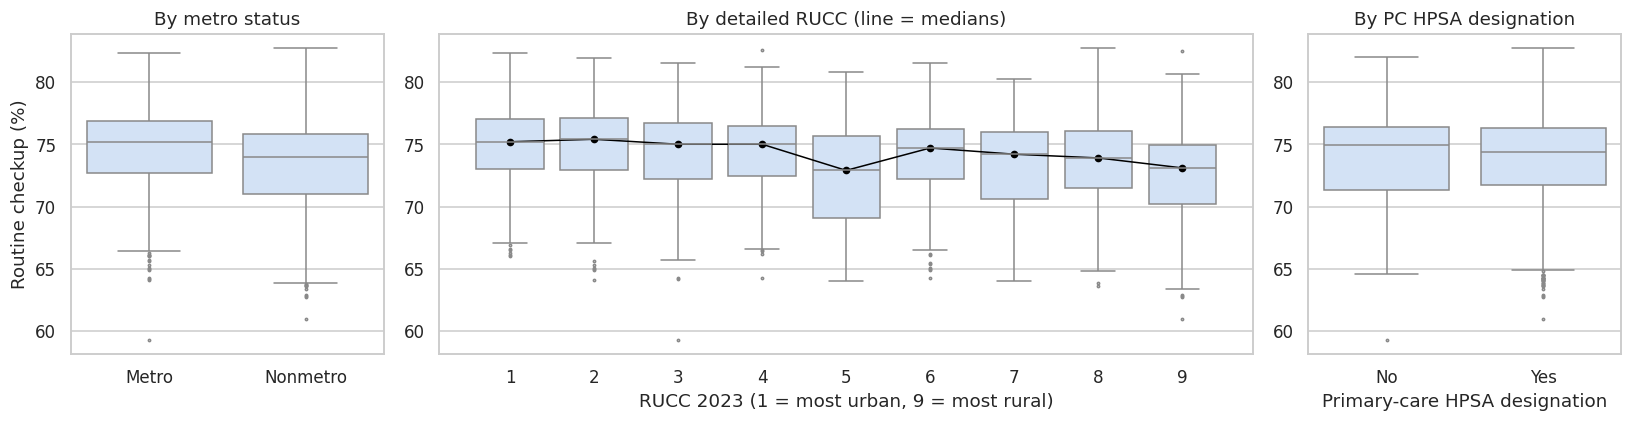

,count,median,mean,std,variable
Metro,954,75.2,74.61,3.39,metro_status
Nonmetro,1561,74.0,73.33,3.61,metro_status
0,351,74.9,73.99,3.37,pc_hpsa_any
1,2164,74.4,73.79,3.62,pc_hpsa_any
1.0,359,75.2,74.79,3.21,rucc_detailed
2.0,313,75.4,74.77,3.44,rucc_detailed
3.0,282,75.0,74.20,3.54,rucc_detailed
4.0,160,75.0,74.22,3.47,rucc_detailed
5.0,58,72.9,72.14,4.40,rucc_detailed
6.0,291,74.7,74.15,3.35,rucc_detailed


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 2.6, 1]})

# boxplot for rucc
sns.boxplot(data=eda, 
            x="rucc_metro_status", 
            y=TARGET, 
            ax=axes[0], 
            color="#cde2fb", 
            fliersize=1.5)
axes[0].set(xlabel="", ylabel="Routine checkup (%)", title="By metro status")

# boxplot for rural urban 
sns.boxplot(data=eda, 
            x=eda["rural_urban_contnm_23"].astype(int), 
            y=TARGET, 
            ax=axes[1], 
            color="#cde2fb", 
            fliersize=1.5)

# add median
med = eda.groupby(eda["rural_urban_contnm_23"].astype(int))[TARGET].median()
axes[1].plot(range(len(med)), 
             med.values, 
             color="black", 
             marker="o", 
             ms=4, lw=1)
axes[1].set(xlabel="RUCC 2023 (1 = most urban, 9 = most rural)", 
            ylabel="", 
            title="By detailed RUCC (line = medians)")

# boxplot for hpsa
sns.boxplot(data=eda, 
            x=eda["pc_hpsa_any"].map({0: "No", 1: "Yes"}), 
            y=TARGET, 
            order=["No", "Yes"],
            ax=axes[2], 
            color="#cde2fb", 
            fliersize=1.5)

axes[2].set(xlabel="Primary-care HPSA designation", 
            ylabel="", 
            title="By PC HPSA designation")
plt.tight_layout()
savefig("eda_target_by_group")
plt.show()


group_summary = pd.concat([
    eda.groupby("rucc_metro_status")[TARGET].agg(["count", "median", "mean", "std"]).assign(variable="metro_status"),
    eda.groupby("pc_hpsa_any")[TARGET].agg(["count", "median", "mean", "std"]).assign(variable="pc_hpsa_any"),
    eda.groupby("rural_urban_contnm_23")[TARGET].agg(["count", "median", "mean", "std"]).assign(variable="rucc_detailed"),
])
group_summary.round(2)

**Takeaways – group differences.**
- Metro counties have higher checkup rates than nonmetro counties (median 75.2 vs 74.0; mean gap ≈ 1.3 pp).
- Across **detailed RUCC**, the pattern is not linear in the code. Codes 1–4 are flat (~75), code 5 dips (72.9, n = 58), code 6 rebounds (74.7), and codes 7–9 decline. The step from 4 to 5 is not equivalent to the step from 5 to 6, which is why detailed RUCC is one-hot encoded rather than treated as a continuous number.
- Counties **without** a primary-care HPSA designation have a slightly *higher* median than designated counties (74.9 vs 74.4), but the distributions overlap almost completely. HPSA designation status on its own carries little univariate signal for this outcome.

### 4.6 Nonlinearity: binned scatterplots against the target

Each panel shows individual counties (light) and the mean target within 20 equal-count bins of the feature (dark line). A straight binned line suggests a linear model is adequate for that feature; bends, plateaus, or thresholds favor SVR or boosting. Rate features are plotted on a log1p axis, matching the transformation the linear models use.

In [25]:
def binned_line(x, yv, bins=20):
    """ draws the binned-means trend line """
    d = pd.DataFrame({"x": x, 
                      "y": yv}).dropna()
    # assign each county to one of 20 bins
    d["bin"] = pd.qcut(d["x"].rank(method="first"), bins, labels=False)
    # give an average x and average y for each bin
    return d.groupby("bin")[["x", "y"]].mean()

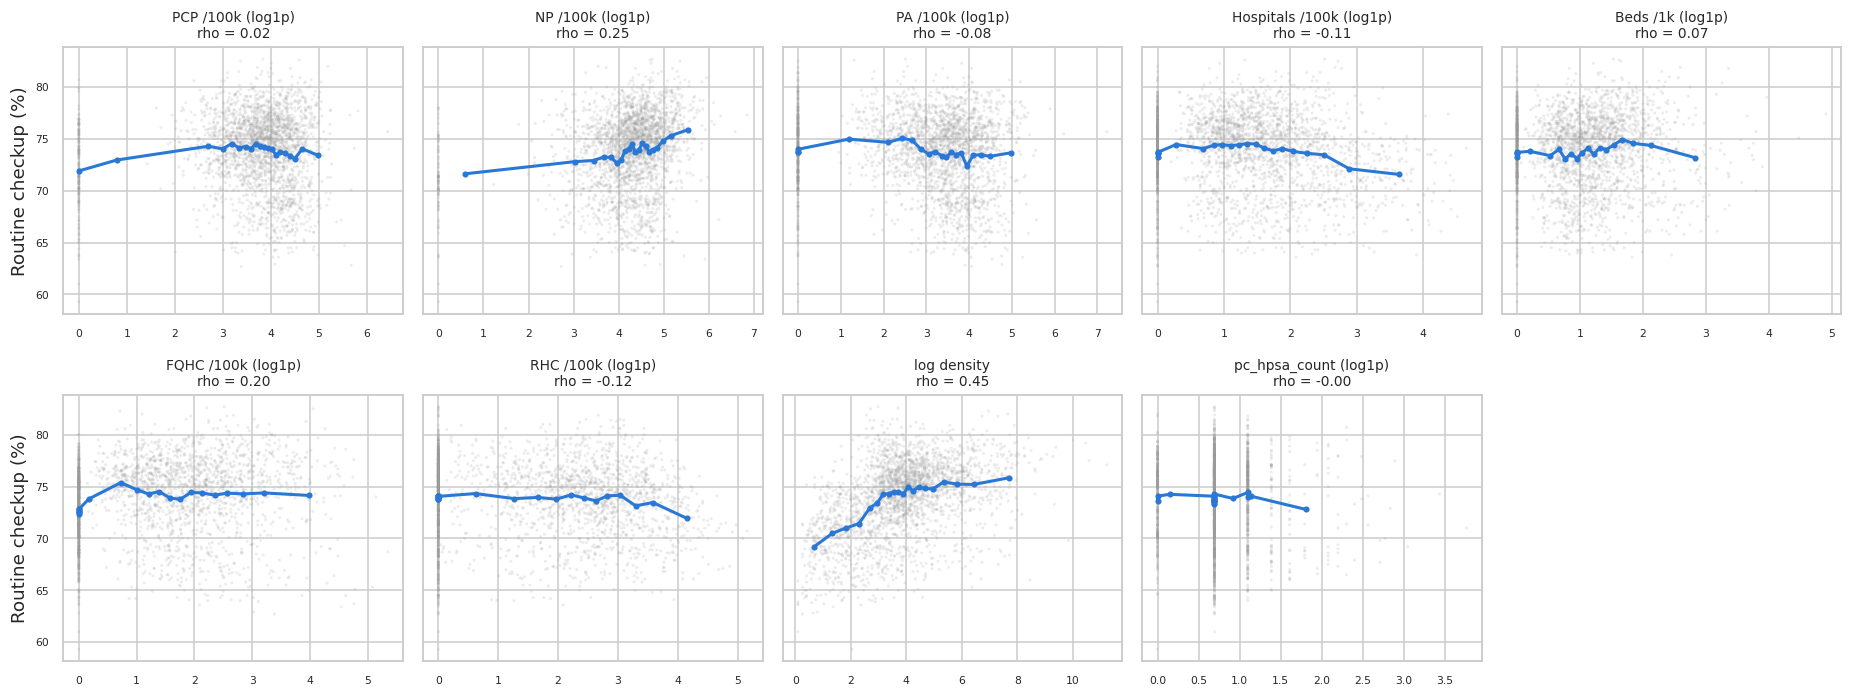

In [26]:
# features for the scatter plots
scatter_feats = RATE_FEATURES + ["log_population_density", "pc_hpsa_count"]

fig, axes = plt.subplots(2, 5, figsize=(17, 6.5), sharey=True)

# for each scatter plot
for ax, c in zip(axes.flat, scatter_feats):
    # plot rate features (except log density) on the log scale
    xv = np.log1p(eda[c]) if c in RATE_FEATURES + ["pc_hpsa_count"] else eda[c]
    
    ax.scatter(xv, eda_y, s=4, alpha=0.18, color="#9a9a9a", edgecolors="none")
    # calculate bins (on the same scale as the dots)
    b = binned_line(xv, eda_y)
    ax.plot(b["x"], b["y"], color=MODEL_COLORS["Elastic Net"], lw=2, marker="o", ms=3)
    # calculate the correlation
    rho = eda[[c, TARGET]].corr(method="spearman").iloc[0, 1]
    # use the short titles again for readabiity
    label = short.get(c, c) + (" (log1p)" if c in RATE_FEATURES + ["pc_hpsa_count"] else "")
    
    ax.set(title=f"{label}\nrho = {rho:.2f}", xlabel="")
    ax.title.set_size(9)
    ax.tick_params(labelsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel("Routine checkup (%)")
for ax in axes.flat[len(scatter_feats):]:
    ax.axis("off")
    
plt.tight_layout()
savefig("eda_binned_scatter")
plt.show()

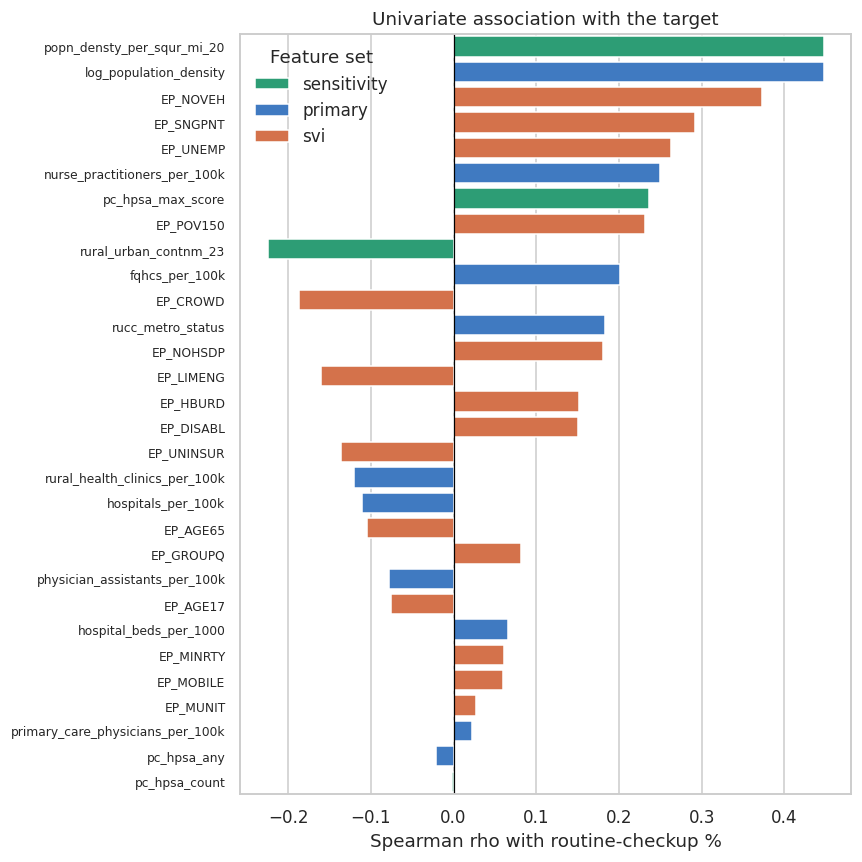

In [27]:
# Spearman correlation of every candidate feature with the target
def target_corr(f):
    """ calculate correlation with target variable"""
    # change metro to integer again
    x = (eda[f] == "Metro").astype(int) if f == "rucc_metro_status" else eda[f]
    return x.corr(eda[TARGET], method="spearman")


target_rho = pd.DataFrame([
    {"feature": f,
     "group": "primary" if f in PRIMARY_FEATURES else ("svi" if f in SVI_FEATURES else "sensitivity"),
     # calculate correlation
     "rho_with_target": target_corr(f)}
    for f in ALL_MODEL_FEATURES
]).sort_values("rho_with_target", key=abs, ascending=False)


fig, ax = plt.subplots(figsize=(8, 8))
pal = {"primary": MODEL_COLORS["Elastic Net"], 
       "sensitivity": MODEL_COLORS["Gradient Boosting"], 
       "svi": MODEL_COLORS["SVR"]}

sns.barplot(data=target_rho, 
            y="feature", 
            x="rho_with_target", 
            hue="group", 
            palette=pal, 
            dodge=False, 
            ax=ax)

ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Spearman rho with routine-checkup %", 
       ylabel="",
       title="Univariate association with the target")

ax.tick_params(axis="y", labelsize=8)
ax.legend(title="Feature set", frameon=False)

plt.tight_layout()
savefig("eda_target_rho_all")
plt.show()

**Takeaways – nonlinearity.**
- **Log population density** is by far the strongest univariate correlate (ρ = 0.45). Its relationship is clearly nonlinear: the target rises steeply across sparsely populated counties and then plateaus.
- The provider and facility rates have weak univariate associations (|ρ| ≤ 0.25). Several are non-monotone. |Threshold- and plateau-shaped patterns like these favor SVR and boosting over a purely linear model.
- Several SVI indicators (minority share, poverty, uninsured) correlate with the target about as strongly as density does. That is the main reason the SVI specification is expected to improve accuracy, and also why it is kept as a sensitivity analysis: PLACES' small-area estimates are built partly from these same demographic and socioeconomic inputs.

### 4.7 EDA decisions carried into modeling

| Finding | Decision |
|---|---|
| Rate features heavily right-skewed with many zeros | `log1p` tuned as a hyperparameter (linear/SVR); raw for trees |
| CT/Wrangell missingness is structural and tiny | within-fold median imputation + missing-indicator columns; keep the counties |
| HPSA score missing ⇔ no designation | constant fill (0) paired with `pc_hpsa_any`, sensitivity spec only |
| Detailed RUCC is non-monotone in the target | one-hot encode in the rurality sensitivity spec |
| Alternatives highly redundant with primary features | one-change-at-a-time sensitivity specifications |
| Strong nonlinearity in density, threshold patterns in facility rates | compare against SVR (RBF) and Gradient Boosting |
| 88% of target variance is between states | report state-grouped CV alongside random CV; examine state-level residuals |
| Primary-feature VIFs all < 4 | keep all 10 primary features |

## 5. Pre-processing for Modeling

### 5.1 Cross-Validation Setup

Three CV splitters are used, all on the training set only:

- `cv_tune` – random 5-fold, used inside every `GridSearchCV`.
- `cv_eval` – random 5-fold with a different seed, used to report each tuned model's performance opposed to just best_score_.
- `cv_state` – `GroupKFold` by state

In [28]:
cv_tune = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_eval = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE + 1)
cv_state = GroupKFold(n_splits=N_SPLITS)

# inspect the folds that are grouped by state
fold_rows = []
for i, (tr, va) in enumerate(cv_state.split(X_train, y_train, groups_train)):
    fold_rows.append({
        "fold": i + 1,
        "n_train": len(tr),
        "n_val": len(va),
        "n_val_states": groups_train.iloc[va].nunique(),
        "val_states": ", ".join(sorted(groups_train.iloc[va].unique())),
    })

pd.DataFrame(fold_rows)

,fold,n_train,n_val,n_val_states,val_states
0,1,2012,503,9,"AK, CA, CT, MN, NV, SD, TX, WA, WI"
1,2,2014,501,11,"AL, DE, GA, IL, MS, MT, NJ, PA, RI, WV, WY"
2,3,2010,505,10,"IA, MA, MD, ME, ND, NY, OH, OK, SC, VA"
3,4,2014,501,11,"CO, DC, FL, HI, MI, MO, NC, NE, NM, UT, VT"
4,5,2010,505,10,"AR, AZ, ID, IN, KS, KY, LA, NH, OR, TN"


### 5.2 Preprocessing Pipeline

There are five types of features that require different preprocessing steps. All steps live inside the pipeline, so imputation medians and scaling parameters are learned within each CV training fold.

1. **Rate** – non-negative, right-skewed rates are eligible for a log1p transformation (toggled as a hyperparameter for Elastic Net and SVR); median imputation with a missing-indicator column; scaled for Elastic Net and SVR.
2. **Numeric** – median imputation with a missing-indicator column; scaled for Elastic Net and SVR.
3. **Categorical** – most-frequent imputation, then one-hot encoding, including `rural_urban_contnm_23`: its codes are ordered, but the gap between codes 2 and 3 is not equivalent to the gap between 7 and 8, so it is not treated as a continuous number (Section 4.5 also shows the target is not monotone across codes).
4. **Binary** – most-frequent imputation.
5. **HPSA score** – `pc_hpsa_max_score` no-designation counties are filled with a constant 0, and the score is only ever used together with `pc_hpsa_any`; tree models can split on the indicator directly.

**Connecticut / structural AHRF missingness.** The nine Connecticut regions (7 in training, 2 in test) have no 2022 AHRF resource values. They stay in the data, the values are median-imputed within each training fold, and the `add_indicator=True` columns let every model learn a separate offset for "AHRF values unavailable" rather than treating the imputed value as real.

In [29]:
# rate-type features eligible for log1p
LOG_CANDIDATES = RATE_FEATURES + ["pc_hpsa_count"]


def make_log_transformer():
    """ helper function to make log1p transformation for eligible rate features """
    return FunctionTransformer(np.log1p, feature_names_out="one-to-one")


def build_preprocessor(features, log_rates=True, scale=True):
    # separate the feature types
    num, binary, cat, score = split_feature_types(features)
    rate = [f for f in num if f in LOG_CANDIDATES]
    other = [f for f in num if f not in LOG_CANDIDATES]

    if score:
        # a no-designation fill value is only meaningful together with the designation indicator
        # redundant for trees but does not affect the modeling process
        assert "pc_hpsa_any" in features, "pc_hpsa_max_score must be paired with pc_hpsa_any"

    transformers = []

    # rate feature processing
    if rate:
        transformers.append((
            "rate",
            Pipeline([
                # log transform the eligible rate features if toggled
                ("log", make_log_transformer() if log_rates else "passthrough"),
                # impute with median
                ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                # scale when toggled for elastic net and svm
                ("scale", StandardScaler() if scale else "passthrough"),
            ]),
            rate,
        ))

    # numeric features
    if other:
        transformers.append((
            "num",
            Pipeline([
                # impute with median
                ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                # scale when toggled for elastic net and svm
                ("scale", StandardScaler() if scale else "passthrough"),
            ]),
            other,
        ))

    # hpsa score
    if score:
        transformers.append((
            "hpsa_score",
            Pipeline([
                # missing score == no qualifying designation, so consistent fill, not median
                ("fill_no_designation", SimpleImputer(strategy="constant", fill_value=0)),
                # scale when toggled for elastic net and svm
                ("scale", StandardScaler() if scale else "passthrough"),
            ]),
            score,
        ))

    # binary feature (hspa_any)
    if binary:
        transformers.append((
            "bin",
            # impute with most frequent value
            SimpleImputer(strategy="most_frequent"),
            binary,
        ))

    # categorical features
    if cat:
        transformers.append((
            "cat",
            Pipeline([
                # impute with most frequent value
                ("impute", SimpleImputer(strategy="most_frequent")),
                # one hot encode
                ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore")),
            ]),
            cat,
        ))

    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)

### 5.3 Scoring and Helper Functions

In [30]:
SCORING = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

# one row per model x spec x CV scheme
cv_rows = []
# tuned hyperparameters per model family
best_params = {}  
# tuned (unfitted-on-full-train) pipelines for the primary specification
best_models = {}    

In [31]:
def make_model_pipe(model_name, features, params=None):
    """ build a fresh pipeline for a model family and feature list, optionally with tuned params """
    if model_name == "Dummy":
        pre, est = build_preprocessor(features, log_rates=False, scale=False), DummyRegressor(strategy="median")
    elif model_name == "Elastic Net":
        # log transform the rates and scale numeric values
        pre, est = build_preprocessor(features, log_rates=True, scale=True), ElasticNet(max_iter=20_000, random_state=RANDOM_STATE)
    elif model_name == "SVR":
        # log transform the rates and scale numeric values
        pre, est = build_preprocessor(features, log_rates=True, scale=True), SVR(kernel="rbf")
    elif model_name == "Gradient Boosting":
        # no need to log transform the rates or scale numeric values
        pre, est = build_preprocessor(features, log_rates=False, scale=False), GradientBoostingRegressor(random_state=RANDOM_STATE)
    else:
        raise ValueError(model_name)
    pipe = Pipeline([("preprocess", pre), ("model", est)])
    if params:
        # skip preprocessing params for branches this feature list does not have (e.g. no rate features)
        branches = {name for name, _, _ in pre.transformers}
        params = {k: v for k, v in params.items()
                  if not k.startswith("preprocess__") or k.split("__")[1] in branches}
        pipe.set_params(**params)
    return pipe

In [32]:
def evaluate_cv(model_name, pipe, features, spec="primary", store=True):
    """ score a pipeline on the evaluation folds: random (cv_eval) and state-grouped (cv_state) """
    rows = []
    # random then state grouped
    for cv_name, cv, g in [("random", cv_eval, None), ("state_grouped", cv_state, groups_train)]:
        res = cross_validate(clone(pipe), X_train[features], y_train, groups=g, cv=cv,
                             scoring=SCORING, return_train_score=True, n_jobs=-1)
        rows.append({
            "model": model_name, 
            "spec": spec, 
            "cv": cv_name,
            # flip mae and rmse back after sklearn's selection method
            "MAE_mean": -res["test_MAE"].mean(), 
            "MAE_std": res["test_MAE"].std(),
            "RMSE_mean": -res["test_RMSE"].mean(), 
            "RMSE_std": res["test_RMSE"].std(),
            "R2_mean": res["test_R2"].mean(), 
            "R2_std": res["test_R2"].std(),
            "train_MAE_mean": -res["train_MAE"].mean(),
            # helpful for paired comparisons
            "fold_MAE": -res["test_MAE"],       
        })
    # this store toggle is so we can do quick checks opposed to creating the overall comparison df
    if store:
        cv_rows.extend(rows)
    return pd.DataFrame(rows).drop(columns="fold_MAE")


def show_cv(frame):
    """ displaying the paired comparisons """
    return frame.drop(columns="fold_MAE", errors="ignore").round(3)

## 6. Modeling - Primary Specification

### 6.1 Baseline: Dummy Regressor

The median is the natural constant prediction under absolute-error loss, so `DummyRegressor(strategy="median")` is the benchmark every model must beat.

In [33]:
dummy_pipe = make_model_pipe("Dummy", PRIMARY_FEATURES)
best_models["Dummy"] = dummy_pipe
best_params["Dummy"] = {}
evaluate_cv("Dummy", dummy_pipe, PRIMARY_FEATURES).round(3)

,model,spec,cv,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,train_MAE_mean
0,Dummy,primary,random,2.813,0.064,3.631,0.063,-0.027,0.009,2.813
1,Dummy,primary,state_grouped,3.056,0.744,3.794,0.884,-0.698,0.766,2.783


### 6.2 Elastic Net

In [34]:
enet_pipe = make_model_pipe("Elastic Net", PRIMARY_FEATURES)

# hyperparameters are alpha, l1 ratio, and whether or not we log transform the rate features
enet_grid = {
    "model__alpha": np.logspace(-3, 0.5, 15),
    "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
    "preprocess__rate__log": [make_log_transformer(), "passthrough"],
}

enet_search = GridSearchCV(
    enet_pipe, enet_grid,
    scoring=SCORING, refit="MAE",
    cv=cv_tune, n_jobs=-1,
    return_train_score=True,
)
enet_search.fit(X_train[PRIMARY_FEATURES], y_train)

best_params["Elastic Net"] = enet_search.best_params_
best_models["Elastic Net"] = make_model_pipe("Elastic Net", PRIMARY_FEATURES, enet_search.best_params_)

enet_best_log = "log1p" if enet_search.best_params_["preprocess__rate__log"] != "passthrough" else "raw"
print("Best alpha:   ", round(enet_search.best_params_["model__alpha"], 4))
print("Best l1_ratio:", enet_search.best_params_["model__l1_ratio"])
print("Rate features:", enet_best_log)
print(f"Best tuning-fold MAE: {-enet_search.best_score_:.3f}")

Best alpha:    0.01
Best l1_ratio: 1.0
Rate features: log1p
Best tuning-fold MAE: 2.334


In [35]:
evaluate_cv("Elastic Net", best_models["Elastic Net"], PRIMARY_FEATURES).round(3)

,model,spec,cv,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,train_MAE_mean
0,Elastic Net,primary,random,2.329,0.052,2.999,0.078,0.299,0.034,2.317
1,Elastic Net,primary,state_grouped,2.569,0.448,3.226,0.526,-0.248,0.484,2.292


**Tuning diagnostics.** How sensitive is CV MAE to `l1_ratio` and to the log transform? (best alpha for each combination)

In [36]:
enet_res = pd.DataFrame(enet_search.cv_results_)
enet_res["rate_transform"] = enet_res["param_preprocess__rate__log"].map(lambda v: "raw" if v == "passthrough" else "log1p")
enet_res["MAE"] = -enet_res["mean_test_MAE"]

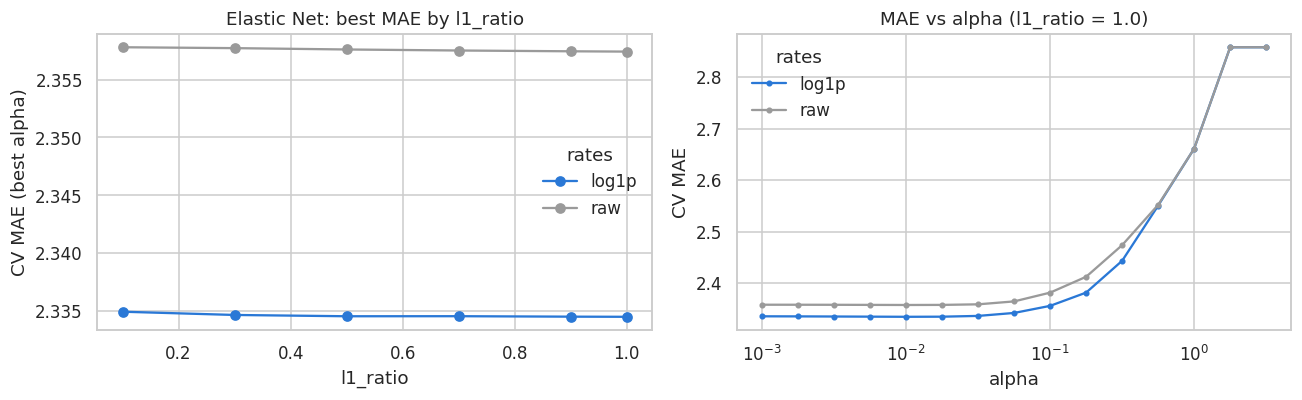

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
best_by_l1 = enet_res.groupby(["param_model__l1_ratio", "rate_transform"])["MAE"].min().unstack()
best_by_l1.plot(marker="o", 
                ax=axes[0], 
                color=[MODEL_COLORS["Elastic Net"], "#9a9a9a"])
axes[0].set(xlabel="l1_ratio", 
            ylabel="CV MAE (best alpha)", 
            title="Elastic Net: best MAE by l1_ratio")
axes[0].legend(title="rates", frameon=False)

best_l1 = enet_search.best_params_["model__l1_ratio"]
sub = enet_res[(enet_res["param_model__l1_ratio"] == best_l1)]
for t, g in sub.groupby("rate_transform"):
    axes[1].plot(g["param_model__alpha"].astype(float), 
                 g["MAE"], marker="o", 
                 ms=3, label=t,
                 color=MODEL_COLORS["Elastic Net"] if t == "log1p" else "#9a9a9a")
axes[1].set_xscale("log")
axes[1].set(xlabel="alpha", 
            ylabel="CV MAE", 
            title=f"MAE vs alpha (l1_ratio = {best_l1})")
axes[1].legend(title="rates", 
               frameon=False)
plt.tight_layout()
savefig("enet_tuning")
plt.show()

In [38]:
print(f"MAE spread across l1_ratio (log1p, best alpha each): "
      f"{best_by_l1['log1p'].max() - best_by_l1['log1p'].min():.4f} percentage points")

MAE spread across l1_ratio (log1p, best alpha each): 0.0004 percentage points


**Coefficients and regularization path** (fit on the full training set, standardized features).

In [39]:
# refit on all training data
enet_full = clone(best_models["Elastic Net"]).fit(X_train[PRIMARY_FEATURES], y_train)
# names of the columns the model actually sees after preprocessing
enet_feat_names = enet_full.named_steps["preprocess"].get_feature_names_out()
# pair each fitted coefficient with its column name
enet_coefs = pd.Series(enet_full.named_steps["model"].coef_, index=enet_feat_names, name="coef")
# sort by size
display(enet_coefs.sort_values(key=abs, ascending=False).round(3).to_frame())

# same training matrix the model was fit on 
Xt_enet = enet_full.named_steps["preprocess"].transform(X_train[PRIMARY_FEATURES])
# refit with 60 different alpha values
path_alphas, path_coefs, _ = enet_path(
    Xt_enet - Xt_enet.mean(axis=0), y_train - y_train.mean(), l1_ratio=best_l1,
    alphas=np.logspace(-3, 0.5, 60),
)

,coef
log_population_density,2.241
physician_assistants_per_100k,-0.785
rucc_metro_status_Nonmetro,0.591
fqhcs_per_100k,0.532
rural_health_clinics_per_100k,0.508
hospital_beds_per_1000,0.288
primary_care_physicians_per_100k,-0.285
missingindicator_fqhcs_per_100k,-0.222
nurse_practitioners_per_100k,0.214
missingindicator_log_population_density,0.211


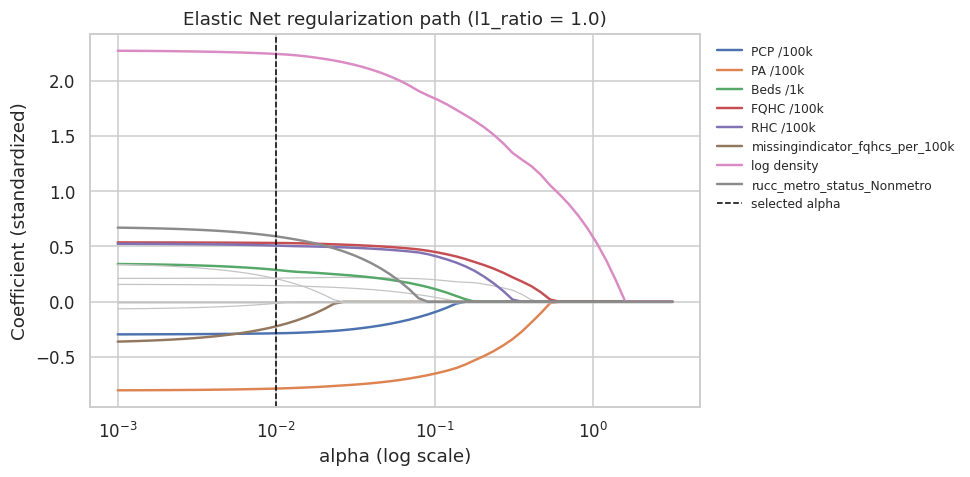

In [40]:
fig, ax = plt.subplots(figsize=(9, 4.5))
top = enet_coefs.abs().sort_values(ascending=False).index[:8]
for name, coef_line in zip(enet_feat_names, path_coefs):
    is_top = name in top
    ax.plot(path_alphas, 
            coef_line, 
            lw=1.6 if is_top else 0.8, 
            color=None if is_top else "#c3c3c3",
            label=short.get(name, name) if is_top else None)
ax.axvline(enet_search.best_params_["model__alpha"], 
           color="black", 
           ls="--", lw=1, 
           label="selected alpha")
ax.set_xscale("log")
ax.set(xlabel="alpha (log scale)", 
       ylabel="Coefficient (standardized)",
       title=f"Elastic Net regularization path (l1_ratio = {best_l1})")
ax.legend(fontsize=8, 
          frameon=False, 
          bbox_to_anchor=(1.01, 1), 
          loc="upper left")
plt.tight_layout()
savefig("enet_regularization_path")
plt.show()

**Elastic Net interpretation.**
- The tuned model has `alpha = 0.01` and **`l1_ratio = 1.0`**, so the tuned Elastic Net is effectively a **Lasso** solution; the search found no benefit from the ridge (L2) component. The tuning curve shows MAE is essentially flat across `l1_ratio`, so the data do not strongly prefer Lasso over Elastic Net. With mild collinearity (all VIF < 4), there is little for the L2 component to stabilize.
- `log1p` rates perform better than raw rates, consistent with the skew analysis.
- **Log density** dominates the coefficients (+2.2 pp per SD). Conditional on density, NP, FQHC, RHC, and bed supply have small positive coefficients, while PA and PCP supply have small negative ones. These are partial associations among correlated, county-level features, and cannot be interpreted as causal effects. The negative PA/PCP signs likely reflect small remote counties with inflated per-capita rates and low checkup rates (Section 4.4).
- Lasso zeroes out `pc_hpsa_any` and `hospitals_per_100k` (beds carry the hospital signal). Most of the AHRF missing-indicator columns are also zeroed, because they are identical for the 7 CT regions and Lasso keeps one or two of them.
- Elastic Net beats the baseline by ~0.48 pp MAE (2.33 vs 2.81) with R² ≈ 0.30 under random CV. Train and validation MAE are almost identical, so the linear model underfits rather than overfits.

### 6.3 Support Vector Regression (SVR)

RBF-kernel SVR, tuned over `C` (regularization), `epsilon` (width of the zero-loss tube, in percentage points), `gamma` (kernel width), and the log transform of the rate features per the exploratory analysis.

In [41]:
svr_pipe = make_model_pipe("SVR", PRIMARY_FEATURES)

svr_grid = {
    "model__C": [0.3, 1, 3, 10, 30],
    "model__epsilon": [0.1, 0.5, 1.0],
    "model__gamma": ["scale", 0.01, 0.03, 0.1],
    "preprocess__rate__log": [make_log_transformer(), "passthrough"],
}

svr_search = GridSearchCV(
    svr_pipe, svr_grid,
    scoring=SCORING, refit="MAE",
    cv=cv_tune, n_jobs=-1,
    return_train_score=True,
)
svr_search.fit(X_train[PRIMARY_FEATURES], y_train)

best_params["SVR"] = svr_search.best_params_
best_models["SVR"] = make_model_pipe("SVR", PRIMARY_FEATURES, svr_search.best_params_)

print({k: (v if k != "preprocess__rate__log" else ("raw" if v == "passthrough" else "log1p"))
       for k, v in svr_search.best_params_.items()})
print(f"Best tuning-fold MAE: {-svr_search.best_score_:.3f}")

{'model__C': 10, 'model__epsilon': 0.5, 'model__gamma': 'scale', 'preprocess__rate__log': 'log1p'}
Best tuning-fold MAE: 2.116


In [42]:
evaluate_cv("SVR", best_models["SVR"], PRIMARY_FEATURES).round(3)

,model,spec,cv,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,train_MAE_mean
0,SVR,primary,random,2.105,0.027,2.756,0.035,0.408,0.018,1.916
1,SVR,primary,state_grouped,2.455,0.562,3.081,0.639,-0.157,0.538,1.855


In [43]:
svr_res = pd.DataFrame(svr_search.cv_results_)
svr_res["rate_transform"] = svr_res["param_preprocess__rate__log"].map(lambda v: "raw" if v == "passthrough" else "log1p")
svr_res["MAE"] = -svr_res["mean_test_MAE"]
svr_res["gamma"] = svr_res["param_model__gamma"].astype(str)

bp = svr_search.best_params_
best_t = "raw" if bp["preprocess__rate__log"] == "passthrough" else "log1p"

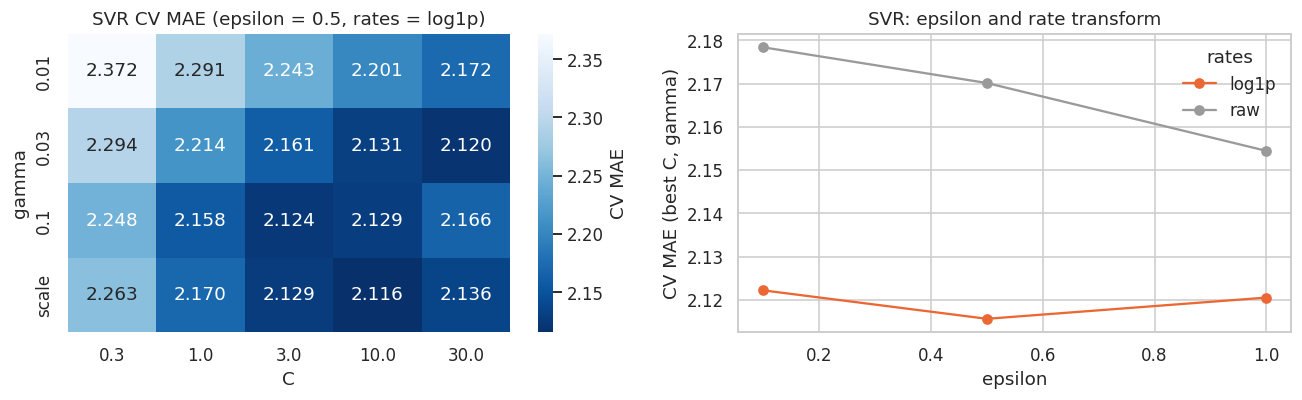

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
# set up data structure for the heatmap
heat = (svr_res[(svr_res["param_model__epsilon"] == bp["model__epsilon"]) & (svr_res["rate_transform"] == best_t)]
        .pivot_table(index="gamma", columns="param_model__C", values="MAE"))
sns.heatmap(heat, 
            annot=True, 
            fmt=".3f", 
            cmap="Blues_r", 
            ax=axes[0], 
            cbar_kws={"label": "CV MAE"})
axes[0].set(xlabel="C", 
            ylabel="gamma", 
            title=f"SVR CV MAE (epsilon = {bp['model__epsilon']}, rates = {best_t})")

eps_t = svr_res.groupby(["param_model__epsilon", "rate_transform"])["MAE"].min().unstack()
eps_t.plot(marker="o", 
           ax=axes[1], 
           color=[MODEL_COLORS["SVR"], "#9a9a9a"])
axes[1].set(xlabel="epsilon", 
            ylabel="CV MAE (best C, gamma)", 
            title="SVR: epsilon and rate transform")
axes[1].legend(title="rates", 
               frameon=False)

plt.tight_layout()
savefig("svr_tuning")
plt.show()

**SVR interpretation.** The best configuration is an RBF kernel with `C = 10`, `epsilon = 0.5`, `gamma = "scale"`, and `log1p` rates. Errors within ±0.5 pp are ignored, which is small relative to the ~2 pp MAE. Performance is fairly flat across neighboring `C`/`gamma` values, so the result does not hinge on one iteration of the grid by chance. SVR improves on Elastic Net by ~0.22 pp MAE (2.11 vs 2.33; R² 0.41 vs 0.30) with only a modest train–validation gap (≈ 0.19 pp). That gain is consistent with the nonlinear density and threshold patterns seen in EDA.

### 6.4 Gradient Boosting

Tree ensembles do not need scaling or the log transform. The grid covers learning rate, number of trees, tree depth, and loss (squared error vs. Huber, which is less sensitive to outlying counties). `subsample=0.8` and `min_samples_leaf=20` add regularization (leaf size is fixed to keep the grid affordable).

In [45]:
gb_pipe = make_model_pipe("Gradient Boosting", PRIMARY_FEATURES)

gb_grid = {
    "model__learning_rate": [0.03, 0.1],
    "model__n_estimators": [300, 600],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_leaf": [20],
    "model__subsample": [0.8],
    "model__loss": ["squared_error", "huber"],
}

gb_search = GridSearchCV(
    gb_pipe, gb_grid,
    scoring=SCORING, refit="MAE",
    cv=cv_tune, n_jobs=-1,
    return_train_score=True,
)
gb_search.fit(X_train[PRIMARY_FEATURES], y_train)

best_params["Gradient Boosting"] = gb_search.best_params_
best_models["Gradient Boosting"] = make_model_pipe("Gradient Boosting", PRIMARY_FEATURES, gb_search.best_params_)

print(gb_search.best_params_)
print(f"Best tuning-fold MAE: {-gb_search.best_score_:.3f}")

{'model__learning_rate': 0.03, 'model__loss': 'huber', 'model__max_depth': 4, 'model__min_samples_leaf': 20, 'model__n_estimators': 300, 'model__subsample': 0.8}
Best tuning-fold MAE: 2.106


In [46]:
evaluate_cv("Gradient Boosting", best_models["Gradient Boosting"], PRIMARY_FEATURES).round(3)

,model,spec,cv,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,train_MAE_mean
0,Gradient Boosting,primary,random,2.116,0.064,2.776,0.054,0.399,0.019,1.687
1,Gradient Boosting,primary,state_grouped,2.461,0.597,3.079,0.649,-0.170,0.577,1.653


**Train vs. validation loss by boosting stage.** One tuning fold is held out within the training set, and the tuned model is refit with many more trees to show where validation error stops improving.

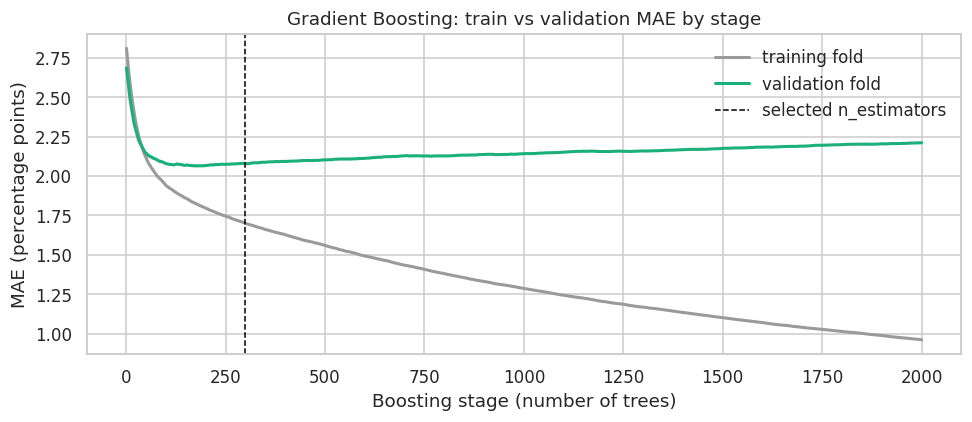

In [47]:
tr_i, va_i = next(cv_tune.split(X_train))
gb_curve = make_model_pipe("Gradient Boosting", 
                           PRIMARY_FEATURES, 
                           {**gb_search.best_params_, "model__n_estimators": 2000})
gb_curve.fit(X_train[PRIMARY_FEATURES].iloc[tr_i], y_train.iloc[tr_i])
pre_c, mdl_c = gb_curve.named_steps["preprocess"], gb_curve.named_steps["model"]
Xtr_c = pre_c.transform(X_train[PRIMARY_FEATURES].iloc[tr_i])
Xva_c = pre_c.transform(X_train[PRIMARY_FEATURES].iloc[va_i])
train_curve = [mean_absolute_error(y_train.iloc[tr_i], p) for p in mdl_c.staged_predict(Xtr_c)]
val_curve = [mean_absolute_error(y_train.iloc[va_i], p) for p in mdl_c.staged_predict(Xva_c)]

fig, ax = plt.subplots(figsize=(9, 4))
stages = np.arange(1, len(train_curve) + 1)
ax.plot(stages, 
        train_curve, 
        color="#9a9a9a", 
        lw=2, 
        label="training fold")
ax.plot(stages, 
        val_curve, 
        color=MODEL_COLORS["Gradient Boosting"], 
        lw=2, 
        label="validation fold")
ax.axvline(gb_search.best_params_["model__n_estimators"], 
           color="black", 
           ls="--", lw=1, 
           label="selected n_estimators")
ax.set(xlabel="Boosting stage (number of trees)", 
       ylabel="MAE (percentage points)",
       title="Gradient Boosting: train vs validation MAE by stage")
ax.legend(frameon=False)

plt.tight_layout()
savefig("gb_loss_curve")
plt.show()

In [48]:
print(f"Validation MAE minimum at stage {int(np.argmin(val_curve)) + 1} ({min(val_curve):.3f}); "
      f"at selected stage: {val_curve[gb_search.best_params_['model__n_estimators'] - 1]:.3f}")

Validation MAE minimum at stage 171 (2.064); at selected stage: 2.080


**Gradient Boosting interpretation.** The best configuration uses a small learning rate (0.03), 300 depth-4 trees, `min_samples_leaf = 20`, and **Huber loss**, which down-weights the large residuals from outlying counties. The loss curve shows validation MAE bottoming out around 170 trees (2.064). At the selected 300 trees it is essentially unchanged (2.080), so the model is not over-boosted. Training error keeps falling, though, and the train–validation gap (≈ 0.43 pp) is the largest of the three families. CV performance (MAE 2.12, R² 0.40) is statistically indistinguishable from SVR.

### 6.5 Results Comparison and Model Selection

All numbers below are cross-validated on the training set (`cv_eval` and `cv_state` folds).

In [49]:
cv_df = pd.DataFrame(cv_rows)
primary_cv = cv_df[cv_df["spec"] == "primary"].copy()
primary_cv["model"] = pd.Categorical(primary_cv["model"], MODEL_ORDER, ordered=True)
primary_cv = primary_cv.sort_values(["cv", "model"])
primary_cv["overfit_gap (val MAE - train MAE)"] = primary_cv["MAE_mean"] - primary_cv["train_MAE_mean"]
show_cv(primary_cv.drop(columns="spec"))

,model,cv,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,train_MAE_mean,overfit_gap (val MAE - train MAE)
0,Dummy,random,2.813,0.064,3.631,0.063,-0.027,0.009,2.813,0.000
2,Elastic Net,random,2.329,0.052,2.999,0.078,0.299,0.034,2.317,0.012
4,SVR,random,2.105,0.027,2.756,0.035,0.408,0.018,1.916,0.189
6,Gradient Boosting,random,2.116,0.064,2.776,0.054,0.399,0.019,1.687,0.429
1,Dummy,state_grouped,3.056,0.744,3.794,0.884,-0.698,0.766,2.783,0.273
3,Elastic Net,state_grouped,2.569,0.448,3.226,0.526,-0.248,0.484,2.292,0.278
5,SVR,state_grouped,2.455,0.562,3.081,0.639,-0.157,0.538,1.855,0.600
7,Gradient Boosting,state_grouped,2.461,0.597,3.079,0.649,-0.170,0.577,1.653,0.808


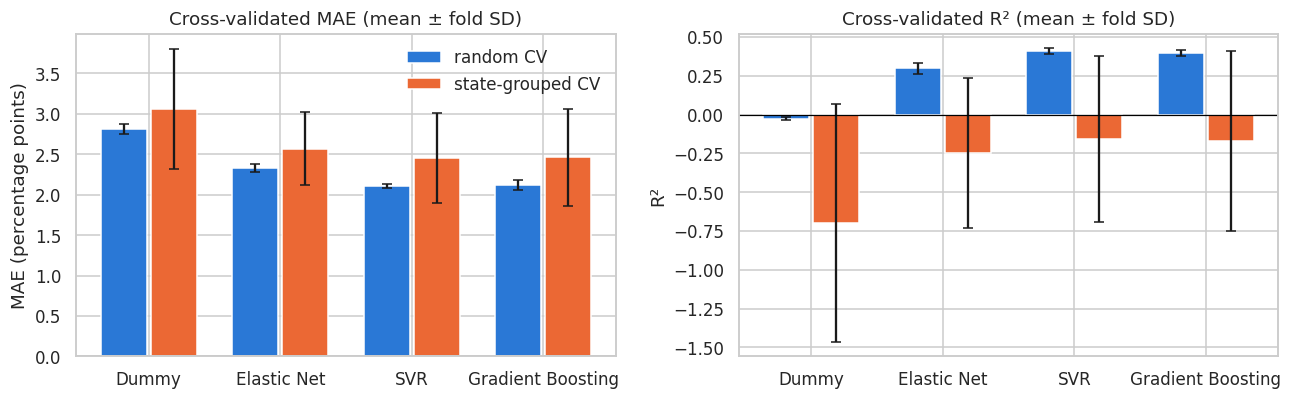

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric, label in [(axes[0], "MAE", "MAE (percentage points)"), (axes[1], "R2", "R²")]:
    w = 0.38
    for k, cvn in enumerate(["random", "state_grouped"]):
        sub = primary_cv[primary_cv["cv"] == cvn].set_index("model").loc[MODEL_ORDER]
        xs = np.arange(len(MODEL_ORDER)) + (k - 0.5) * w
        ax.bar(xs, 
               sub[f"{metric}_mean"], 
               width=w * 0.92, 
               yerr=sub[f"{metric}_std"], 
               capsize=3,
               color=CV_COLORS[cvn], 
               label=cvn.replace("_", "-") + " CV")
    ax.set_xticks(np.arange(len(MODEL_ORDER)), MODEL_ORDER)
    ax.set(ylabel=label, 
           title=f"Cross-validated {label.split(' ')[0]} (mean ± fold SD)")
    ax.axhline(0, 
               color="black", 
               lw=0.8)
axes[0].legend(frameon=False)

plt.tight_layout()
savefig("model_comparison_cv")
plt.show()

**Out-of-fold predictions.** `cross_val_predict` on the evaluation folds gives every training county a prediction from a model that did not see it, which lets us draw predicted-vs-observed and residual plots without touching the test set.

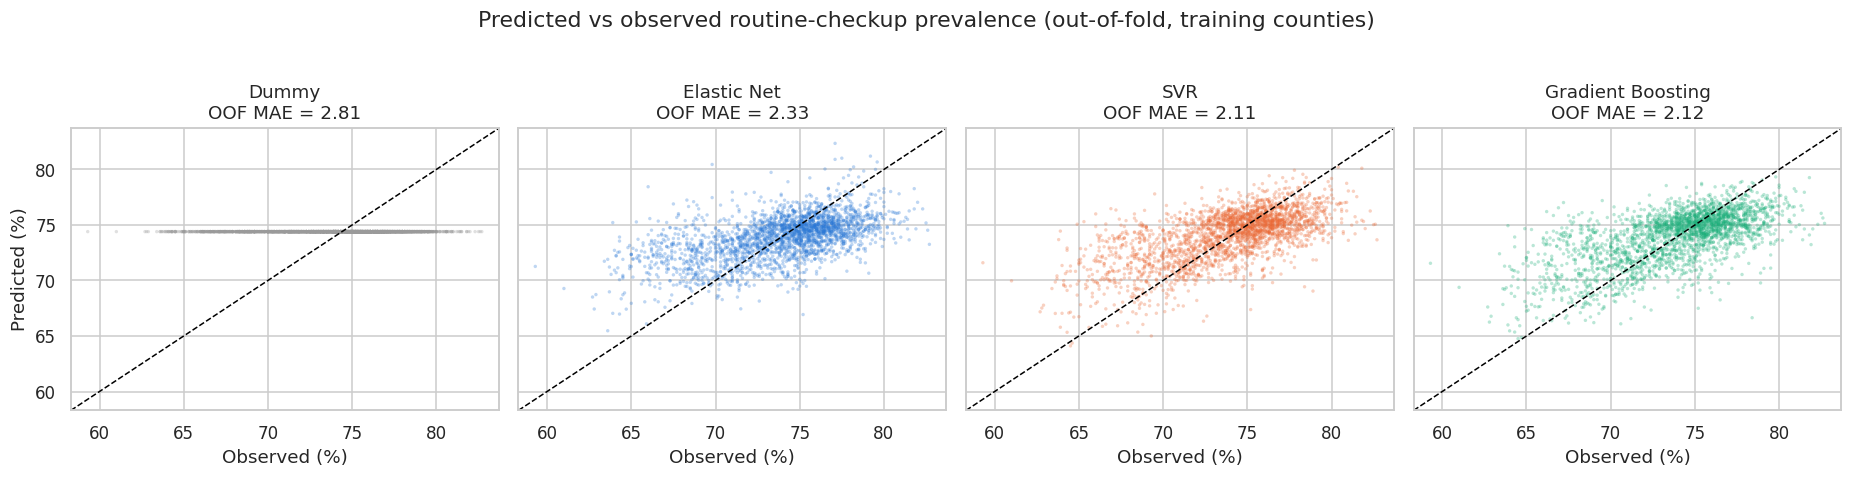

In [51]:
oof_pred = {}
for name in MODEL_ORDER:
    oof_pred[name] = pd.Series(
        cross_val_predict(clone(best_models[name]), X_train[PRIMARY_FEATURES], y_train, cv=cv_eval, n_jobs=-1),
        index=y_train.index,
    )
# observed - predicted
oof_resid = pd.DataFrame({m: y_train - p for m, p in oof_pred.items()})  

lims = (y_train.min() - 1, y_train.max() + 1)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharex=True, sharey=True)
for ax, name in zip(axes, MODEL_ORDER):
    ax.scatter(y_train, 
               oof_pred[name], 
               s=5, 
               alpha=0.3, 
               color=MODEL_COLORS[name], 
               edgecolors="none")
    ax.plot(lims, 
            lims, 
            color="black", 
            lw=1, ls="--")
    mae = mean_absolute_error(y_train, oof_pred[name])
    ax.set(title=f"{name}\nOOF MAE = {mae:.2f}", 
           xlabel="Observed (%)", 
           xlim=lims, ylim=lims)
axes[0].set_ylabel("Predicted (%)")
fig.suptitle("Predicted vs observed routine-checkup prevalence (out-of-fold, training counties)", y=1.03)

plt.tight_layout()
savefig("pred_vs_obs_oof")
plt.show()

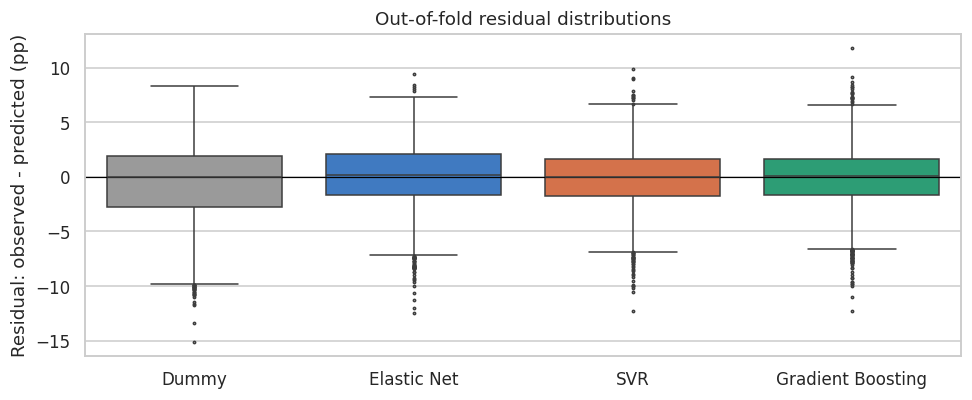

,mean,std,min,25%,50%,75%,max
Dummy,-0.59,3.58,-15.10,-2.80,0.00,1.90,8.30
Elastic Net,-0.00,3.00,-12.44,-1.68,0.21,2.05,9.45
SVR,-0.19,2.75,-12.30,-1.77,-0.00,1.60,9.85
Gradient Boosting,-0.08,2.78,-12.25,-1.63,0.12,1.66,11.76


In [52]:
fig, ax = plt.subplots(figsize=(9, 3.8))
long = oof_resid.melt(var_name="model", 
                      value_name="residual")
sns.boxplot(data=long, 
            x="model", 
            y="residual", 
            hue="model", 
            palette=MODEL_COLORS, 
            order=MODEL_ORDER,
            fliersize=1.5, 
            ax=ax, 
            legend=False)
ax.axhline(0, 
           color="black", 
           lw=0.8)
ax.set(xlabel="", 
       ylabel="Residual: observed - predicted (pp)", 
       title="Out-of-fold residual distributions")

plt.tight_layout()
savefig("residual_boxplots_oof")
plt.show()

oof_resid.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)

**Selection rule.** The final model is the non-baseline model with the lowest mean MAE under random CV (the primary metric and primary validation scheme). Because every model is scored on identical folds, we also report the paired fold-by-fold MAE difference between the winner and the runner-up, and check that the ranking holds under state-grouped CV.

In [53]:
rand_cv = primary_cv[primary_cv["cv"] == "random"].set_index("model")
state_cv = primary_cv[primary_cv["cv"] == "state_grouped"].set_index("model")
ranking = rand_cv.drop(index="Dummy")["MAE_mean"].sort_values()
BEST_MODEL_NAME = ranking.index[0]
RUNNER_UP = ranking.index[1]

paired = rand_cv.loc[RUNNER_UP, "fold_MAE"] - rand_cv.loc[BEST_MODEL_NAME, "fold_MAE"]
paired_state = state_cv.loc[RUNNER_UP, "fold_MAE"] - state_cv.loc[BEST_MODEL_NAME, "fold_MAE"]

print("Random-CV MAE ranking:", ", ".join(f"{m} {v:.3f}" for m, v in ranking.items()))
print("State-CV  MAE ranking:", ", ".join(f"{m} {v:.3f}" for m, v in
                                         state_cv.drop(index='Dummy')['MAE_mean'].sort_values().items()))
print(f"\nSelected model: {BEST_MODEL_NAME}")
print(f"Paired fold MAE advantage over {RUNNER_UP}: random CV {paired.mean():.3f} ± {paired.std():.3f} "
      f"(wins {int((paired > 0).sum())}/5 folds); state CV {paired_state.mean():.3f} ± {paired_state.std():.3f} "
      f"(wins {int((paired_state > 0).sum())}/5 folds)")
print(f"Improvement over Dummy (random CV): {rand_cv.loc['Dummy', 'MAE_mean'] - rand_cv.loc[BEST_MODEL_NAME, 'MAE_mean']:.3f} pp "
      f"({100 * (1 - rand_cv.loc[BEST_MODEL_NAME, 'MAE_mean'] / rand_cv.loc['Dummy', 'MAE_mean']):.1f}% lower MAE)")

FINAL_FEATURES = PRIMARY_FEATURES
final_pipe = best_models[BEST_MODEL_NAME]

Random-CV MAE ranking: SVR 2.105, Gradient Boosting 2.116, Elastic Net 2.329
State-CV  MAE ranking: SVR 2.455, Gradient Boosting 2.461, Elastic Net 2.569

Selected model: SVR
Paired fold MAE advantage over Gradient Boosting: random CV 0.011 ± 0.042 (wins 3/5 folds); state CV 0.006 ± 0.055 (wins 2/5 folds)
Improvement over Dummy (random CV): 0.708 pp (25.2% lower MAE)


**Model comparison and selection.**
- All three model families beat the median baseline under both CV schemes. Under random CV, the best models reduce MAE from 2.81 to ~2.11 pp (≈ 25% lower) and explain ~40% of the variance.
- Under state-grouped CV, however, every model has negative R² (SVR −0.16)**: the access-only model generalizes poorly to states it has not seen.
- **SVR is selected** (random-CV MAE 2.105 vs 2.116 for Gradient Boosting). The margin is very small: SVR wins 3 of 5 paired folds, with an average advantage of 0.011 ± 0.042 pp. The two nonlinear models are effectively tied. SVR has the smaller overfitting gap, which makes it the slightly safer choice. Both clearly outperform Elastic Net, so modeling nonlinearity is worth ~0.2 pp of MAE.
- The out-of-fold plots show the same pattern for every model: predictions are **compressed toward the middle** of the range. Counties with very low observed rates are over-predicted, and counties with very high rates are under-predicted.

## 7. Interpreting the Selected Model

### 7.1 Permutation Importance

Permutation importance is computed **inside the evaluation folds**: the model is fit on four folds and features are permuted in the held-out fold (10 repeats), so importance reflects out-of-sample MAE increase.

In [54]:
perm_rows = []
# for each fold, fit the selected model on the training folds
for fold, (tr, va) in enumerate(cv_eval.split(X_train)):
    m = clone(best_models[BEST_MODEL_NAME]).fit(X_train[PRIMARY_FEATURES].iloc[tr], y_train.iloc[tr])
    # run permutation importance on the held-out fold within the train data
    pi = permutation_importance(m, X_train[PRIMARY_FEATURES].iloc[va], y_train.iloc[va],
                                scoring="neg_mean_absolute_error", n_repeats=10,
                                random_state=RANDOM_STATE, n_jobs=-1)
    # save the average of the 10 shuffles for each feature
    for f, imp in zip(PRIMARY_FEATURES, pi.importances_mean):
        perm_rows.append({"model": BEST_MODEL_NAME, "fold": fold, "feature": f, "importance": imp})

perm_df = pd.DataFrame(perm_rows)
perm_summary = (perm_df.groupby(["model", "feature"])["importance"].agg(["mean", "std"]).reset_index())

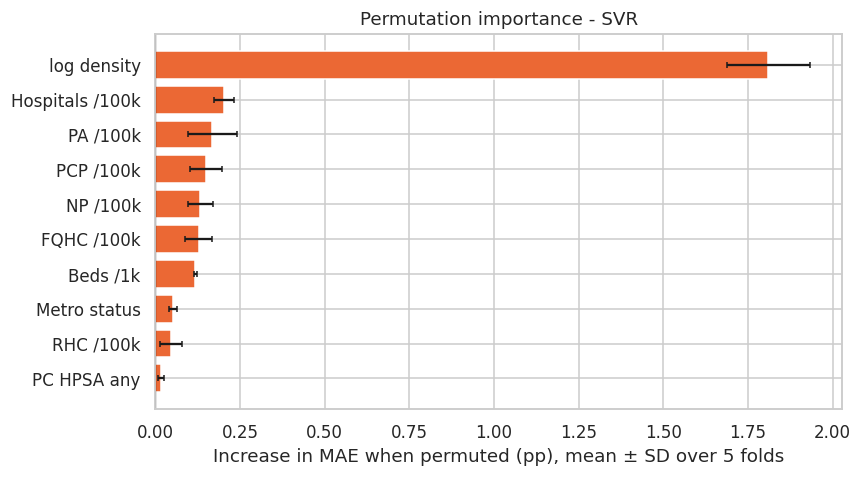

,mean,std
feature,,
log_population_density,1.809,0.122
hospitals_per_100k,0.203,0.030
physician_assistants_per_100k,0.168,0.072
primary_care_physicians_per_100k,0.149,0.048
nurse_practitioners_per_100k,0.134,0.037
fqhcs_per_100k,0.128,0.040
hospital_beds_per_1000,0.118,0.004
rucc_metro_status,0.052,0.013
rural_health_clinics_per_100k,0.047,0.032


In [55]:
# sort features from most to least important
sub = perm_summary.set_index("feature").sort_values("mean", ascending=False)
feat_order = sub.index.tolist()

# horizontal bars with fold-to-fold SD as error bars
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(np.arange(len(feat_order)), sub["mean"], xerr=sub["std"], capsize=2,
        color=MODEL_COLORS[BEST_MODEL_NAME])

# use the shortened feature names again
ax.set_yticks(np.arange(len(feat_order)), [short.get(f, f) for f in feat_order])
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Increase in MAE when permuted (pp), mean ± SD over 5 folds",
       title=f"Permutation importance - {BEST_MODEL_NAME}")

plt.tight_layout()
savefig("permutation_importance")
plt.show()

sub[["mean", "std"]].round(3)

#### Permutation importance for the other model families

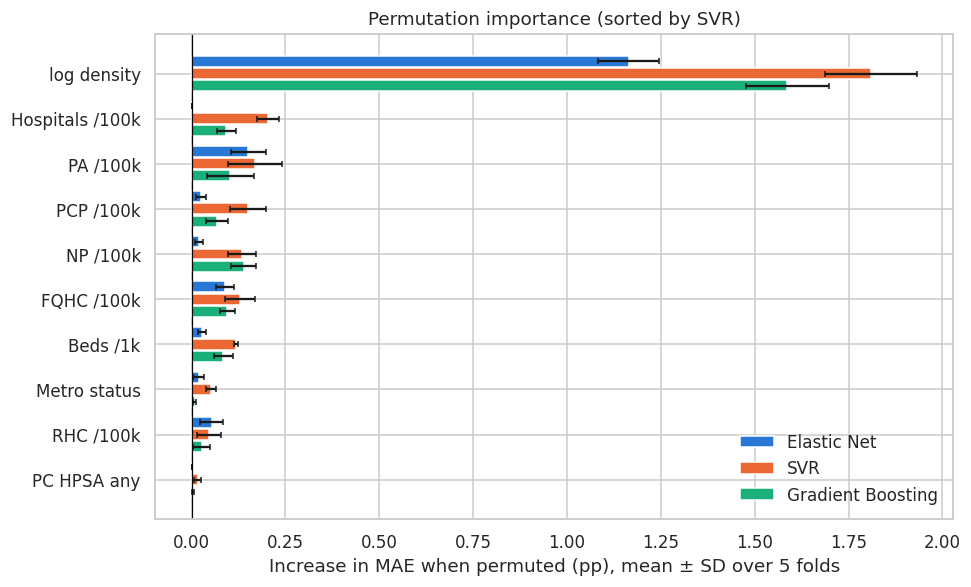

model,Elastic Net,Gradient Boosting,SVR
feature,,,
log_population_density,1.165,1.586,1.809
hospitals_per_100k,-0.000,0.092,0.203
physician_assistants_per_100k,0.150,0.103,0.168
primary_care_physicians_per_100k,0.025,0.067,0.149
nurse_practitioners_per_100k,0.019,0.139,0.134
fqhcs_per_100k,0.089,0.095,0.128
hospital_beds_per_1000,0.028,0.085,0.118
rucc_metro_status,0.019,0.008,0.052
rural_health_clinics_per_100k,0.054,0.027,0.047


In [56]:
perm_rows = []
# for each model
for name in ["Elastic Net", "SVR", "Gradient Boosting"]:
    # for each fold in the model
    for fold, (tr, va) in enumerate(cv_eval.split(X_train)):
        m = clone(best_models[name]).fit(X_train[PRIMARY_FEATURES].iloc[tr], y_train.iloc[tr])
        # run permutation importance on the held out set within the train data
        pi = permutation_importance(m, X_train[PRIMARY_FEATURES].iloc[va], y_train.iloc[va],
                                    scoring="neg_mean_absolute_error", n_repeats=10,
                                    random_state=RANDOM_STATE, n_jobs=-1)
        # save the average of the 10 folds shuffles for each feature in each model
        for f, imp in zip(PRIMARY_FEATURES, pi.importances_mean):
            perm_rows.append({"model": name, "fold": fold, "feature": f, "importance": imp})
perm_df = pd.DataFrame(perm_rows)
perm_summary = (perm_df.groupby(["model", "feature"])["importance"].agg(["mean", "std"]).reset_index())

feat_order = (perm_summary[perm_summary["model"] == BEST_MODEL_NAME]
              .sort_values("mean", ascending=False)["feature"].tolist())
fig, ax = plt.subplots(figsize=(9, 5.5))
names3 = ["Elastic Net", "SVR", "Gradient Boosting"]

# build the horizontal bars 
h = 0.27
for k, name in enumerate(names3):
    sub = perm_summary[perm_summary["model"] == name].set_index("feature").loc[feat_order]
    ys = np.arange(len(feat_order)) + (k - 1) * h
    ax.barh(ys, sub["mean"], height=h * 0.9, xerr=sub["std"], capsize=2, color=MODEL_COLORS[name], label=name)

# use the shortened feature names again
ax.set_yticks(np.arange(len(feat_order)), [short.get(f, f) for f in feat_order])
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Increase in MAE when permuted (pp), mean ± SD over 5 folds",
       title=f"Permutation importance (sorted by {BEST_MODEL_NAME})")
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
savefig("perm_importance_all_models")
plt.show()

perm_summary.pivot(index="feature", 
                   columns="model", 
                   values="mean").loc[feat_order].round(3)

### 7.2 Partial Dependence of the Selected Model

Partial dependence shows the average predicted checkup rate as one feature varies with others held at their observed values, for the four most important numeric features.

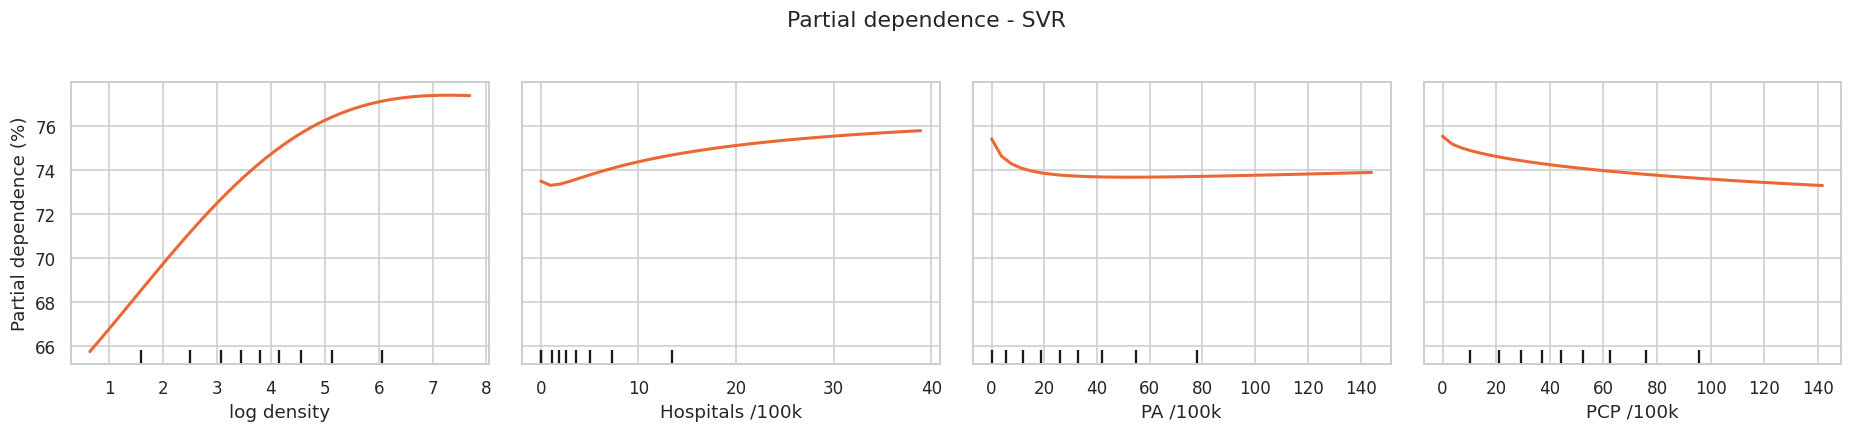

In [57]:
final_full = clone(final_pipe).fit(X_train[FINAL_FEATURES], y_train)
numeric_top = [f for f in feat_order if f not in CATEGORICAL_FEATURES + BINARY_FEATURES][:4]
pdp_X = X_train[FINAL_FEATURES].dropna()

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
PartialDependenceDisplay.from_estimator(
    final_full, pdp_X, numeric_top, ax=axes, grid_resolution=40,
    percentiles=(0.02, 0.98), line_kw={"color": MODEL_COLORS[BEST_MODEL_NAME], "lw": 2},
)
for k, (ax, f) in enumerate(zip(axes, numeric_top)):
    ax.set_xlabel(short.get(f, f))
    if k:
        ax.set_ylabel("")
axes[0].set_ylabel("Partial dependence (%)")
fig.suptitle(f"Partial dependence - {BEST_MODEL_NAME}", y=1.03)
plt.tight_layout()
savefig("partial_dependence_best")
plt.show()

### 7.3 Feature-Group Ablation

For each construct in the primary specification, the selected model (same hyperparameters) is re-scored with that group **dropped**, and also with **only** that group. Differences are paired by fold. A positive change in MAE when a group is dropped means the remaining features cannot fully substitute for it.

In [58]:
# store all results from the model to establish a baseline MAE
full_rows = {r["cv"]: r for r in cv_rows if r["model"] == BEST_MODEL_NAME and r["spec"] == "primary"}

abl_rows = []
# loop over four groups in primary 
for g, gfeats in PRIMARY_GROUPS.items():
    # create two lists - one that's only the feature and one that's everything else
    for variant, feats in [("drop", [f for f in FINAL_FEATURES if f not in gfeats]), ("only", gfeats)]:
        # build pipeline with same hypertuned parameters
        pipe = make_model_pipe(BEST_MODEL_NAME, feats, best_params[BEST_MODEL_NAME])
        # score the model 
        for cv_name, cv, gr in [("random", cv_eval, None), ("state_grouped", cv_state, groups_train)]:
            res = cross_validate(pipe, X_train[feats], y_train, groups=gr, cv=cv,
                                 scoring={"MAE": "neg_mean_absolute_error"}, n_jobs=-1)
            fold_mae = -res["test_MAE"]
            # fold by fold comparison 
            delta = fold_mae - full_rows[cv_name]["fold_MAE"]
            abl_rows.append({"group": g, "variant": variant, "features": ", ".join(feats), "cv": cv_name,
                             "MAE_mean": fold_mae.mean(), "delta_MAE_vs_full": delta.mean(), "delta_sd": delta.std()})
ablation = pd.DataFrame(abl_rows)

In [59]:
SPEC_LABELS = {"hpsa_count_alt": "HPSA count", "hpsa_score_alt": "HPSA score",
             "rurality_alt": "Detailed rurality", "density_alt": "Raw density", "svi": "Add 16 SVI"}
GROUP_LABELS = {"provider_supply": "Provider supply", "healthcare_infrastructure": "Healthcare infrastructure",
              "provider_shortage": "Provider shortage", "geographic_access_context": "Geographic/access context"}

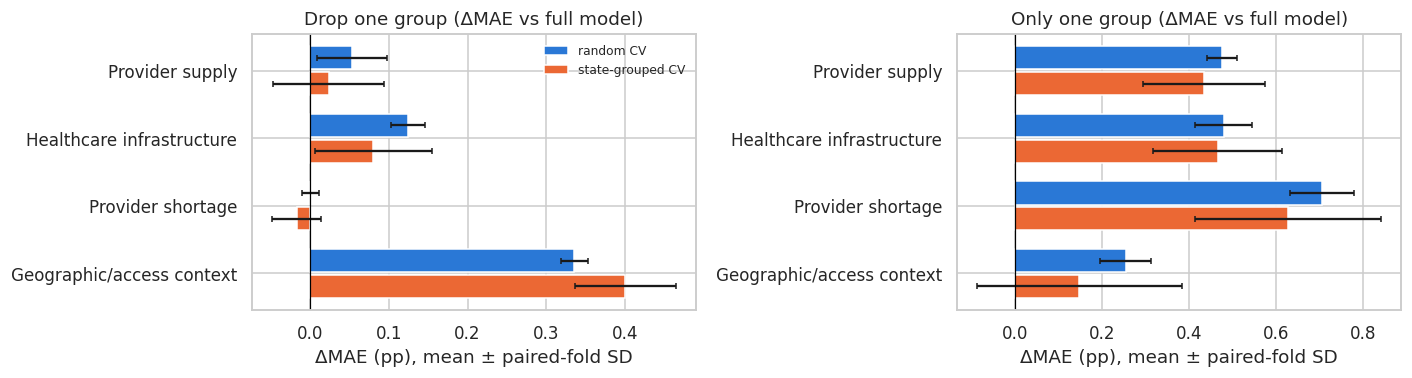

MAE_mean               delta_MAE_vs_full              
cv                                  random state_grouped            random state_grouped
variant group                                                                           
drop    geographic_access_context    2.441         2.856             0.336         0.401
        healthcare_infrastructure    2.229         2.535             0.124         0.080
        provider_shortage            2.105         2.437            -0.000        -0.018
        provider_supply              2.158         2.478             0.053         0.023
only    geographic_access_context    2.359         2.603             0.254         0.148
        healthcare_infrastructure    2.584         2.920             0.479         0.465
        provider_shortage            2.810         3.082             0.705         0.627
        provider_supply              2.580         2.889             0.475         0.434

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, variant, ttl in [(axes[0], "drop", "Drop one group (ΔMAE vs full model)"),
                         (axes[1], "only", "Only one group (ΔMAE vs full model)")]:
    sub = ablation[ablation["variant"] == variant]
    w = 0.38
    gnames = list(PRIMARY_GROUPS)
    for k, cvn in enumerate(["random", "state_grouped"]):
        s = sub[sub["cv"] == cvn].set_index("group").loc[gnames]
        ys = np.arange(len(gnames)) + (k - 0.5) * w
        ax.barh(ys, 
                s["delta_MAE_vs_full"], 
                height=w * 0.9, 
                xerr=s["delta_sd"], 
                capsize=2,
                color=CV_COLORS[cvn], 
                label=cvn.replace("_", "-") + " CV")
    ax.set_yticks(np.arange(len(gnames)), [GROUP_LABELS[g] for g in gnames])
    ax.invert_yaxis(); ax.axvline(0, color="black", lw=0.8)
    ax.set(xlabel="ΔMAE (pp), mean ± paired-fold SD", title=ttl)
axes[0].legend(frameon=False, fontsize=8)

plt.tight_layout()
savefig("group_ablation")
plt.show()

ablation.pivot_table(index=["variant", "group"], columns="cv", values=["MAE_mean", "delta_MAE_vs_full"]).round(3)

**What drives the predictions?**
- **Population density is the dominant predictor.** Permuting it raises MAE by 1.2–1.8 pp, roughly 10× more than any other single feature. 
- The provider and facility rates each contribute modestly with the most consistent signals coming from PA, NP, FQHC, and hospital/bed supply. In the SVR's partial dependence, hospital supply has a small positive slope, while PA and PCP supply show slightly negative slopes once density is held constant.
- **Primary-care HPSA designation does not contribute significantly.** Dropping it changes MAE by 0.0000.
- **Group ablation** confirms this ranking at the construct level. Dropping geographic access context hurts most (+0.34 pp random, +0.40 pp state-grouped), followed by healthcare infrastructure and provider supply. Dropping provider shortage changes nothing. Geography alone already reaches MAE 2.36, so it captures ~65% of the full model's improvement over the baseline. The resource variables add the remaining ~0.25 pp. A resource group used on its own (the "only" bars) does far worse than dropping it from the full model would suggest.

## 8. Sensitivity Specifications

Each alternative specification from Section 2.2 is scored with the **selected model** and with **Elastic Net** (as the interpretable linear reference), both using the hyperparameters tuned on the primary specification. Change in MAE is paired by fold against the primary specification for the same model.

In [61]:
sens_models = list(dict.fromkeys([BEST_MODEL_NAME, "Elastic Net"]))
sens_rows = []
# loop over every speicifcation x model
for spec, feats in FEATURE_SPECS.items():
    for name in sens_models:
        # skip primary, already did that
        if spec == "primary":
            continue
        # run with the hyperparameters tuned on the primary
        pipe = make_model_pipe(name, feats, best_params[name])
        # then evaluate
        evaluate_cv(name, pipe, feats, spec=spec)

# rebuild the results table
cv_df = pd.DataFrame(cv_rows)
for spec in FEATURE_SPECS:
    for name in sens_models:
        for cvn in ["random", "state_grouped"]:
            # the result from the new model 
            r = cv_df[(cv_df.model == name) & (cv_df.spec == spec) & (cv_df.cv == cvn)].iloc[0]
            # the result from the primary
            base = cv_df[(cv_df.model == name) & (cv_df.spec == "primary") & (cv_df.cv == cvn)].iloc[0]
            # paired comparison
            d = r["fold_MAE"] - base["fold_MAE"]
            # save the mean performance metrics and find how many folds improved
            sens_rows.append({"spec": spec, 
                              "model": name, 
                              "cv": cvn, 
                              "n_features": len(FEATURE_SPECS[spec]),
                              "MAE_mean": r["MAE_mean"], 
                              "R2_mean": r["R2_mean"],
                              "delta_MAE_vs_primary": d.mean(), 
                              "delta_sd": d.std(),
                              "folds_better": int((d < 0).sum())})
            
sensitivity = pd.DataFrame(sens_rows)
sensitivity.pivot_table(index=["spec"], columns=["model", "cv"], values="delta_MAE_vs_primary").loc[list(FEATURE_SPECS)].round(3)

model          Elastic Net                  SVR              
cv                  random state_grouped random state_grouped
spec                                                         
primary              0.000         0.000  0.000         0.000
hpsa_count_alt      -0.009        -0.011 -0.011         0.021
hpsa_score_alt      -0.005         0.016 -0.001         0.045
rurality_alt        -0.023        -0.015 -0.005        -0.003
density_alt          0.273         0.335  0.313         0.364
svi                 -0.425        -0.413 -0.482        -0.331

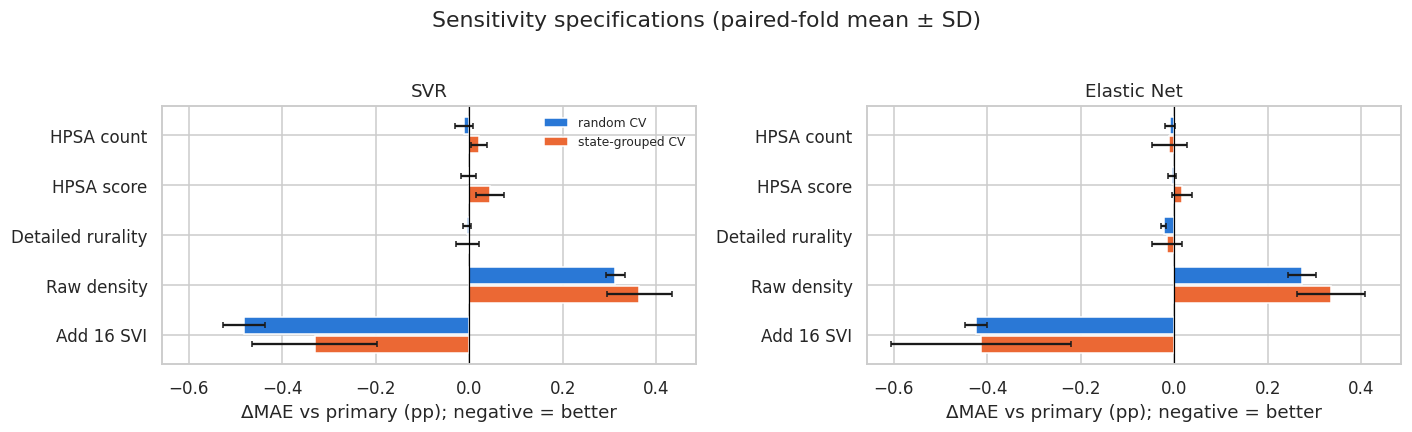

,spec,model,cv,n_features,MAE_mean,R2_mean,delta_MAE_vs_primary,delta_sd,folds_better
0,primary,SVR,random,10,2.105,0.408,0.000,0.000,0
1,primary,SVR,state_grouped,10,2.455,-0.157,0.000,0.000,0
2,primary,Elastic Net,random,10,2.329,0.299,0.000,0.000,0
3,primary,Elastic Net,state_grouped,10,2.569,-0.248,0.000,0.000,0
4,hpsa_count_alt,SVR,random,10,2.094,0.413,-0.011,0.019,4
5,hpsa_count_alt,SVR,state_grouped,10,2.476,-0.179,0.021,0.017,1
6,hpsa_count_alt,Elastic Net,random,10,2.321,0.306,-0.009,0.011,3
7,hpsa_count_alt,Elastic Net,state_grouped,10,2.559,-0.235,-0.011,0.038,4
8,hpsa_score_alt,SVR,random,11,2.104,0.411,-0.001,0.016,4
9,hpsa_score_alt,SVR,state_grouped,11,2.500,-0.190,0.045,0.030,1


In [62]:
specs_alt = [s for s in FEATURE_SPECS if s != "primary"]

fig, axes = plt.subplots(1, len(sens_models), figsize=(6.5 * len(sens_models), 3.8), sharex=True)

axes = np.atleast_1d(axes)
for ax, name in zip(axes, sens_models):
    w = 0.38
    for k, cvn in enumerate(["random", "state_grouped"]):
        s = sensitivity[(sensitivity.model == name) & (sensitivity.cv == cvn)].set_index("spec").loc[specs_alt]
        ys = np.arange(len(specs_alt)) + (k - 0.5) * w
        ax.barh(ys, 
                s["delta_MAE_vs_primary"], 
                height=w * 0.9, 
                xerr=s["delta_sd"], 
                capsize=2,
                color=CV_COLORS[cvn], 
                label=cvn.replace("_", "-") + " CV")
    ax.set_yticks(np.arange(len(specs_alt)), [SPEC_LABELS[s] for s in specs_alt])
    ax.invert_yaxis(); ax.axvline(0, 
                                  color="black", 
                                  lw=0.8)
    ax.set(xlabel="ΔMAE vs primary (pp); negative = better", title=name)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Sensitivity specifications (paired-fold mean ± SD)", y=1.03)

plt.tight_layout()
savefig("sensitivity_specs")
plt.show()

sensitivity.round(3)

Does SVI change the interpretation or just the error? 

In [63]:
svi_feats = FEATURE_SPECS["svi"]
svi_perm = []
for fold, (tr, va) in enumerate(cv_eval.split(X_train)):
    # fit with svi features with the same hyperparameters as the primary
    m = make_model_pipe(BEST_MODEL_NAME, svi_feats, best_params[BEST_MODEL_NAME]).fit(X_train[svi_feats].iloc[tr], y_train.iloc[tr])
    # five shuffles to save some time
    pi = permutation_importance(m, X_train[svi_feats].iloc[va], y_train.iloc[va], scoring="neg_mean_absolute_error",
                                n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    svi_perm.append(pd.Series(pi.importances_mean, index=svi_feats))
    
svi_perm = pd.concat(svi_perm, axis=1).agg(["mean", "std"], axis=1).sort_values("mean", ascending=False)
svi_perm["set"] = np.where(svi_perm.index.isin(SVI_FEATURES), "SVI", "primary")

In [64]:
# identify which primary features matter with vs without svi
primary_imp = (perm_summary[perm_summary["model"] == BEST_MODEL_NAME]
               .set_index("feature")["mean"])
svi_imp = svi_perm["mean"]

interp_shift = pd.DataFrame({
    "importance_primary_spec": primary_imp,
    "importance_svi_spec": svi_imp.reindex(primary_imp.index),
})
interp_shift["change"] = interp_shift["importance_svi_spec"] - interp_shift["importance_primary_spec"]
interp_shift["rank_primary_spec"] = interp_shift["importance_primary_spec"].rank(ascending=False).astype(int)
interp_shift["rank_svi_spec"] = svi_imp.rank(ascending=False).reindex(primary_imp.index).astype(int)
interp_shift.sort_values("importance_primary_spec", ascending=False).round(3)

,importance_primary_spec,importance_svi_spec,change,rank_primary_spec,rank_svi_spec
feature,,,,,
log_population_density,1.809,1.119,-0.690,1,1
hospitals_per_100k,0.203,0.035,-0.168,2,21
physician_assistants_per_100k,0.168,0.129,-0.039,3,8
primary_care_physicians_per_100k,0.149,0.031,-0.118,4,24
nurse_practitioners_per_100k,0.134,0.093,-0.040,5,11
fqhcs_per_100k,0.128,0.038,-0.090,6,20
hospital_beds_per_1000,0.118,0.032,-0.086,7,22
rucc_metro_status,0.052,0.010,-0.042,8,25
rural_health_clinics_per_100k,0.047,0.058,0.011,9,15


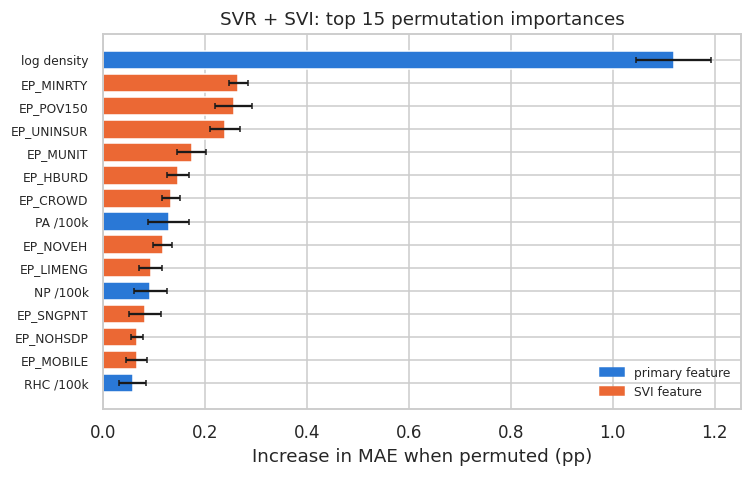

,mean,std,set
log_population_density,1.119,0.073,primary
EP_MINRTY,0.265,0.019,SVI
EP_POV150,0.256,0.036,SVI
EP_UNINSUR,0.239,0.030,SVI
EP_MUNIT,0.174,0.028,SVI
EP_HBURD,0.147,0.021,SVI
EP_CROWD,0.133,0.017,SVI
physician_assistants_per_100k,0.129,0.040,primary
EP_NOVEH,0.118,0.019,SVI
EP_LIMENG,0.093,0.022,SVI


In [67]:
fig, ax = plt.subplots(figsize=(7, 4.5))
top_svi = svi_perm.head(15)
ax.barh(np.arange(len(top_svi)), top_svi["mean"], xerr=top_svi["std"], capsize=2,
        color=[MODEL_COLORS["SVR"] if s == "SVI" else MODEL_COLORS["Elastic Net"] for s in top_svi["set"]])
ax.set_yticks(np.arange(len(top_svi)), [short.get(f, f) for f in top_svi.index])
ax.tick_params(axis="y", labelsize=8)
ax.invert_yaxis()
ax.legend(handles=[Patch(color=MODEL_COLORS["Elastic Net"], label="primary feature"),
                   Patch(color=MODEL_COLORS["SVR"], label="SVI feature")],
          frameon=False, loc="lower right", fontsize=8)
ax.set(xlabel="Increase in MAE when permuted (pp)", title=f"{BEST_MODEL_NAME} + SVI: top 15 permutation importances")

plt.tight_layout()
savefig("permutation_importance_svi")
plt.show()

svi_perm.head(15).round(3)

**Sensitivity specifications.**
- **HPSA count** and **HPSA score** (with no-designation counties filled consistently) change MAE by ≤ 0.04 pp in either direction, inside fold-to-fold noise, for both models. 
- **Detailed RUCC (one-hot)** gives a small, consistent gain for Elastic Net and no change for SVR. The linear model benefits from extra rurality categories, but a nonlinear model already recovers that structure from continuous density.
- **Raw density instead of log density** is clearly worse for both SVR and Elastic Net. Both models are scale-sensitive, and raw density's extreme skew (max ≈ 75,000/sq mi) compresses almost all counties into a narrow band after standardization. This validates the log transform in the primary specification. 
- **Adding the 16 SVI indicators** is the only change that substantially moves performance. SVR MAE falls by ~0.48 pp (to 1.62; R² 0.41 → 0.62) under random CV and by ~0.30 pp under state-grouped CV, with every fold improving. Permutation importance under this specification shows density still ranked first, followed by minority share, poverty (150% FPL), uninsured, multi-unit housing, and housing burden. These SVI measures overlap heavily with the demographic and socioeconomic inputs PLACES uses to construct its small-area estimates. Part of this gain therefore likely reflects reconstruction of the target's estimation model rather than new information about access, so **the primary access-only specification remains the headline result**. The SVI result should be reported as an upper bound on what county context adds.

## 9. Robustness and Failure Analysis

### 9.1 State-Grouped Robustness

Random CV allows counties from the same state to appear in both the training and validation folds; state-grouped CV prevents this by holding out entire states at once. The gap between the two is reported for every model, and the selected model's state-grouped out-of-fold predictions are used to see which held-out states are predicted worst.

In [69]:
gap = (primary_cv.pivot_table(index="model", columns="cv", values="MAE_mean", observed=True)
       .assign(gap=lambda d: d["state_grouped"] - d["random"]).loc[MODEL_ORDER])
gap["gap_pct"] = 100 * gap["gap"] / gap["random"]
r2_gap = primary_cv.pivot_table(index="model", columns="cv", values="R2_mean", observed=True).loc[MODEL_ORDER]
display(pd.concat({"MAE": gap, "R2": r2_gap}, axis=1).round(3))

oof_state = pd.Series(
    cross_val_predict(clone(final_pipe), X_train[FINAL_FEATURES], y_train, groups=groups_train, cv=cv_state, n_jobs=-1),
    index=y_train.index,
)
state_err = pd.DataFrame({
    "state": groups_train,
    "resid_random": y_train - oof_pred[BEST_MODEL_NAME],
    "resid_state": y_train - oof_state,
})
by_state = state_err.groupby("state").agg(
    n=("resid_state", "size"),
    MAE_random=("resid_random", lambda r: r.abs().mean()),
    MAE_state=("resid_state", lambda r: r.abs().mean()),
    bias_state=("resid_state", "mean"),
).sort_values("bias_state")

MAE                                  R2              
cv                random state_grouped    gap gap_pct random state_grouped
model                                                                     
Dummy              2.813         3.056  0.243   8.654 -0.027        -0.698
Elastic Net        2.329         2.569  0.240  10.308  0.299        -0.248
SVR                2.105         2.455  0.350  16.612  0.408        -0.157
Gradient Boosting  2.116         2.461  0.345  16.300  0.399        -0.170

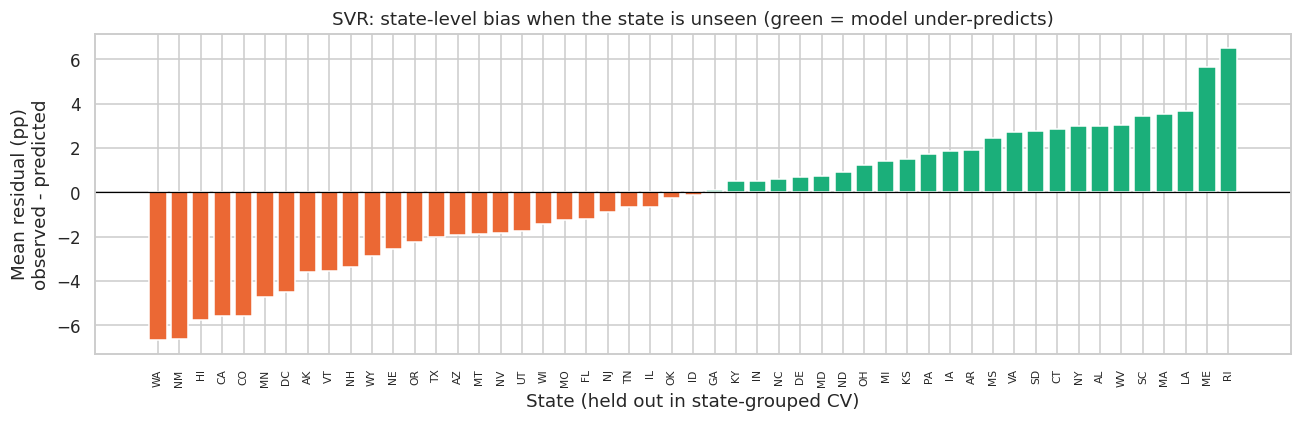

Share of random-CV residual variance explained by state (eta^2): 0.60


,n,MAE_random,MAE_state,bias_state
state,,,,
WA,34,5.96,6.65,-6.65
NM,30,5.65,6.62,-6.62
HI,4,5.97,5.78,-5.78
CA,46,4.52,5.81,-5.59
CO,52,5.10,5.57,-5.57
MN,71,4.12,4.74,-4.72
WV,38,2.57,3.20,3.04
SC,40,3.09,3.45,3.44
MA,10,2.76,3.51,3.51


In [70]:
fig, ax = plt.subplots(figsize=(12, 4))
colors = np.where(by_state["bias_state"] > 0, MODEL_COLORS["Gradient Boosting"], MODEL_COLORS["SVR"])
ax.bar(by_state.index, by_state["bias_state"], color=colors)
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="State (held out in state-grouped CV)", 
       ylabel="Mean residual (pp)\nobserved - predicted",
       title=f"{BEST_MODEL_NAME}: state-level bias when the state is unseen (green = model under-predicts)")
ax.tick_params(axis="x", 
               labelsize=7, 
               rotation=90)
plt.tight_layout()
savefig("state_bias_grouped_cv")
plt.show()

resid_eta = 1 - ((state_err["resid_random"] - state_err.groupby("state")["resid_random"].transform("mean")) ** 2).sum() \
            / ((state_err["resid_random"] - state_err["resid_random"].mean()) ** 2).sum()
print(f"Share of random-CV residual variance explained by state (eta^2): {resid_eta:.2f}")
display(pd.concat([by_state.head(6), by_state.tail(6)]).round(2))

**State-grouped robustness.**
- **The access-only model generalizes poorly to unseen states.** When whole states are held out, SVR MAE rises from 2.105 to 2.455 pp (+0.35 pp, +17%) and R² falls from 0.41 to −0.16. Every model has negative R² under state-grouped CV (Elastic Net −0.25, Gradient Boosting −0.17, Dummy −0.70).
- **A negative R² is a substantive result, not a technicality.** It means that for counties in states the model has never seen, its predictions have larger squared error than simply predicting the held-out counties' own average. The access features cannot recover a new state's overall checkup level, and ~88% of the target's variance lies between states.
- **MAE still beats the grouped baseline** (2.455 vs 3.056 pp), so the model still performs on out of state. The baseline only knows the training-state median, while the R² benchmark is the held-out counties' own mean, which no model has access to. The model ranks counties better than a constant, but it misses each new state's level.
- **The error is systematic by state.** State membership explains ~60% of the random-CV residual variance. With their own state held out, the model over-predicts by 5–7 pp in WA, NM, HI, CA, CO, and MN and under-predicts by 3–6 pp in WV, SC, MA, LA, ME, and RI. State-level factors not captured by county access measures (for example state insurance/Medicaid policy, health-system structure, or the BRFSS/PLACES state-level inputs) are plausible explanations, but they are not tested here.
- **The nonlinear models lose more than Elastic Net** (+0.35 pp for SVR and Gradient Boosting vs +0.24 pp for Elastic Net), suggesting part of their extra flexibility learns state-specific patterns from other counties in the same state.

### 9.2 Failure Analysis

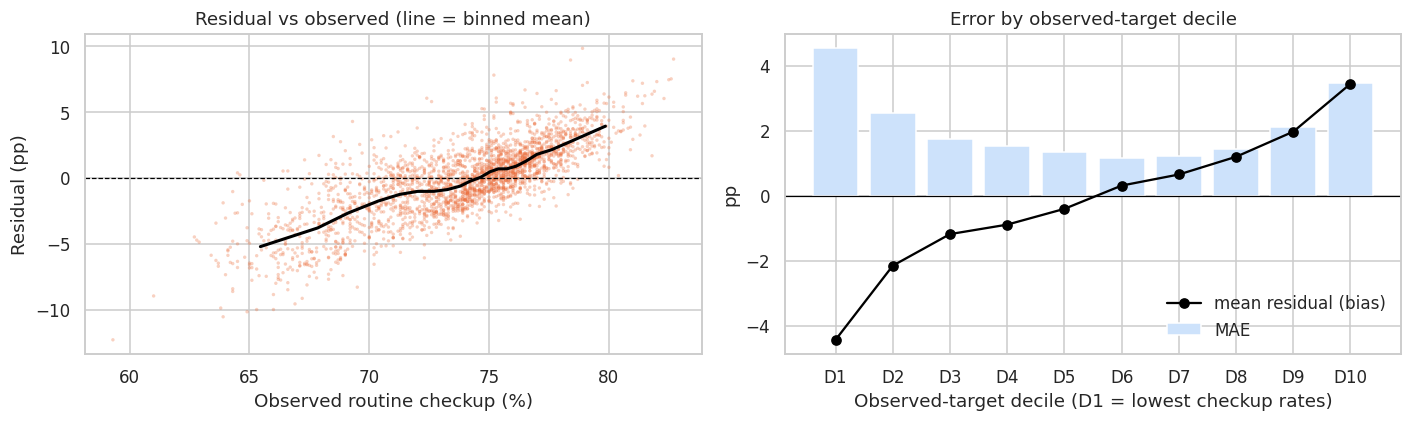

In [71]:
fa = df.loc[idx_train, ID_COLS + [TARGET] + ALL_MODEL_FEATURES].copy()
fa["pred"] = oof_pred[BEST_MODEL_NAME]
fa["resid"] = fa[TARGET] - fa["pred"]
fa["abs_resid"] = fa["resid"].abs()
fa["population"] = shared_analytical.loc[idx_train, "popn_est_22"]   # diagnostic only, not a model feature
fa["ahrf_missing"] = fa["primary_care_physicians_per_100k"].isna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(fa[TARGET], fa["resid"], s=5, alpha=0.3, color=MODEL_COLORS[BEST_MODEL_NAME], edgecolors="none")
b = binned_line(fa[TARGET], fa["resid"])
axes[0].plot(b["x"], b["y"], color="black", lw=2)
axes[0].axhline(0, color="black", lw=0.8, ls="--")
axes[0].set(xlabel="Observed routine checkup (%)", ylabel="Residual (pp)", title="Residual vs observed (line = binned mean)")

fa["target_decile"] = pd.qcut(fa[TARGET], 10, labels=[f"D{i}" for i in range(1, 11)])
dec = fa.groupby("target_decile", observed=True).agg(MAE=("abs_resid", "mean"), bias=("resid", "mean"))
axes[1].bar(dec.index.astype(str), dec["MAE"], color="#cde2fb", label="MAE")
axes[1].plot(dec.index.astype(str), dec["bias"], color="black", marker="o", label="mean residual (bias)")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel="Observed-target decile (D1 = lowest checkup rates)", ylabel="pp", title="Error by observed-target decile")
axes[1].legend(frameon=False)
plt.tight_layout()
savefig("failure_residual_vs_observed")
plt.show()

In [72]:
def err_by(col, labels=None):
    g = fa.groupby(col, observed=True).agg(n=("resid", "size"), MAE=("abs_resid", "mean"), bias=("resid", "mean"),
                                          share_abs_resid_gt_4=("abs_resid", lambda r: (r > 4).mean()))
    g.index = [f"{col} = {i}" for i in g.index]
    return g


fa["population_quintile"] = pd.qcut(fa["population"], 5, labels=["Q1 smallest", "Q2", "Q3", "Q4", "Q5 largest"])
fa["rucc"] = fa["rural_urban_contnm_23"].astype(int)
segment_errors = pd.concat([
    err_by("rucc_metro_status"), err_by("rucc"), err_by("pc_hpsa_any"),
    err_by("population_quintile"), err_by("ahrf_missing"),
])
segment_errors.round(3)

,n,MAE,bias,share_abs_resid_gt_4
rucc_metro_status = Metro,954,2.219,-0.273,0.153
rucc_metro_status = Nonmetro,1561,2.036,-0.134,0.128
rucc = 1,359,2.284,-0.490,0.159
rucc = 2,313,2.249,-0.062,0.153
rucc = 3,282,2.103,-0.231,0.145
rucc = 4,160,2.026,-0.496,0.138
rucc = 5,58,2.751,-1.336,0.293
rucc = 6,291,1.962,-0.217,0.103
rucc = 7,203,1.937,-0.092,0.123
rucc = 8,374,1.966,0.163,0.115


In [73]:
# the 15 counties with the largest absolute out-of-fold errors
worst_cols = ["fips", "state_abbr", "county_name_places", TARGET, "pred", "resid", "population",
              "rucc_metro_status", "pc_hpsa_any", "primary_care_physicians_per_100k", "log_population_density"]
worst = fa.sort_values("abs_resid", ascending=False)[worst_cols].head(15)
display(worst.round(2))
print("States among the 50 largest |residuals|:")
print(fa.nlargest(50, "abs_resid")["state_abbr"].value_counts().head(8).to_dict())

,fips,state_abbr,county_name_places,routine_checkup_pct,pred,resid,population,rucc_metro_status,pc_hpsa_any,primary_care_physicians_per_100k,log_population_density
505,15005,HI,Kalawao,59.3,71.60,-12.30,82.0,Metro,0,0.00,2.05
2910,53069,WA,Wahkiakum,63.9,74.45,-10.55,4688.0,Nonmetro,1,0.00,2.88
1764,35061,NM,Valencia,64.9,75.07,-10.17,78080.0,Metro,1,23.05,4.28
1707,35001,NM,Bernalillo,65.3,75.30,-10.00,672508.0,Metro,1,107.81,6.37
247,08031,CO,Denver,66.0,76.00,-10.00,713252.0,Metro,1,133.05,8.45
222,02275,AK,Wrangell,63.8,73.68,-9.88,2070.0,Nonmetro,1,144.93,0.59
1389,23021,ME,Piscataquis,78.9,69.05,9.85,17417.0,Nonmetro,1,57.42,1.65
359,08047,CO,Gilpin,66.9,76.47,-9.57,5891.0,Metro,1,33.95,3.68
1323,27109,MN,Olmsted,67.2,76.35,-9.15,164020.0,Metro,0,236.56,5.52
1631,28021,MS,Claiborne,82.7,73.66,9.04,8805.0,Nonmetro,1,45.43,2.98


States among the 50 largest |residuals|:
{'CO': 10, 'WA': 7, 'NM': 6, 'CA': 5, 'MN': 3, 'ME': 3, 'NV': 2, 'AL': 2}


**Failure analysis.**
- **Regression toward the mean is the dominant failure mode.** In the lowest decile of observed checkup rates, the model over-predicts by ~4.4 pp on average (MAE ≈ 4.5). In the highest decile, it under-predicts by ~3.4 pp. The access features explain the middle of the distribution but not its tails. *Future work:* features that distinguish the extremes (e.g., state insurance and Medicaid context) could reduce this compression, and quantile regression or recalibration of out-of-fold predictions could be tested to reduce systematic bias at the tails.
- **The worst-predicted counties cluster geographically.** Of the 50 largest errors, 31 are in CO, WA, NM, CA, and MN, mostly over-predictions. Large urban counties such as Denver, Bernalillo, Pierce (WA), and Olmsted (MA) have abundant resources and high density but lower-than-expected checkup rates. Maine counties (Piscataquis, Somerset) and Claiborne, MS, are the main under-predictions. *Future work:* a hierarchical (mixed-effects) model with state random intercepts, explicit state-level covariates (e.g., Medicaid expansion status), or spatial models that account for correlation between nearby counties could capture these state- and region-level offsets; only state-level covariates would help for states absent from training.
- **Extremely small counties** produce several of the largest single errors. Kalawao, HI (population 82) and Loving, TX (population 51) have per-capita rates and PLACES estimates that are both unstable at that size. *Future work:* empirical-Bayes smoothing of per-capita rates, weighting counties by population or by the precision of the PLACES estimate, or flagging counties below a population threshold would limit the influence of these unstable values.
- **By segment:** RUCC 5 (nonmetro, urban population ≥ 20k, not adjacent to a metro area; n = 58) has the highest MAE (2.75) and the strongest over-prediction bias. The largest-population quintile also has elevated error (MAE 2.38, bias −0.64), driven by the western urban counties above. Nonmetro counties are predicted slightly *better* than metro counties (2.04 vs 2.22). *Future work:* per-capita rates overstate access in regional hubs whose providers also serve surrounding counties, so catchment-based access measures (e.g., two-step floating catchment area or travel-time-based provider access) could better represent effective supply in these segments.
- **The structurally missing Connecticut regions are not a problem.** Their errors are small (MAE 1.40, n = 7), so imputation plus missing indicators is an adequate treatment. *Future work:* future AHRF releases that report values for the planning-region geography would let these counties use observed rather than imputed values.

## 10. Final Holdout Test Evaluation

The selected model (SVR), its hyperparameters, and the primary feature specification were selected and fixed in Section 6.5 using cross-validation. This is the single use of the holdout test set. This locked model is evaluated, and the median baseline is included as a reference point. 

In [74]:
print(f"Selected model: {BEST_MODEL_NAME}")

# evaluate finalmodel, but use the Dummy baseline is a reference point
test_rows, test_preds = [], {}
for name in [BEST_MODEL_NAME, "Dummy"]:
    m = clone(best_models[name]).fit(X_train[FINAL_FEATURES], y_train)
    p = m.predict(X_test[FINAL_FEATURES])
    test_preds[name] = p
    test_rows.append({
        "model": name,
        "role": "selected model" if name == BEST_MODEL_NAME else "baseline reference",
        "test_MAE": mean_absolute_error(y_test, p),
        "test_RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "test_R2": r2_score(y_test, p),
        "cv_random_MAE": rand_cv.loc[name, "MAE_mean"],
        "cv_state_MAE": state_cv.loc[name, "MAE_mean"],
    })
test_results = pd.DataFrame(test_rows).set_index("model")
test_results.round(3)

Selected model: SVR


,role,test_MAE,test_RMSE,test_R2,cv_random_MAE,cv_state_MAE
model,,,,,,
SVR,selected model,2.053,2.696,0.427,2.105,2.455
Dummy,baseline reference,2.820,3.602,-0.023,2.813,3.056


SVR test MAE 2.053 (95% bootstrap CI 1.921-2.186)
Improvement over Dummy: 0.768 pp (95% CI 0.617-0.904)


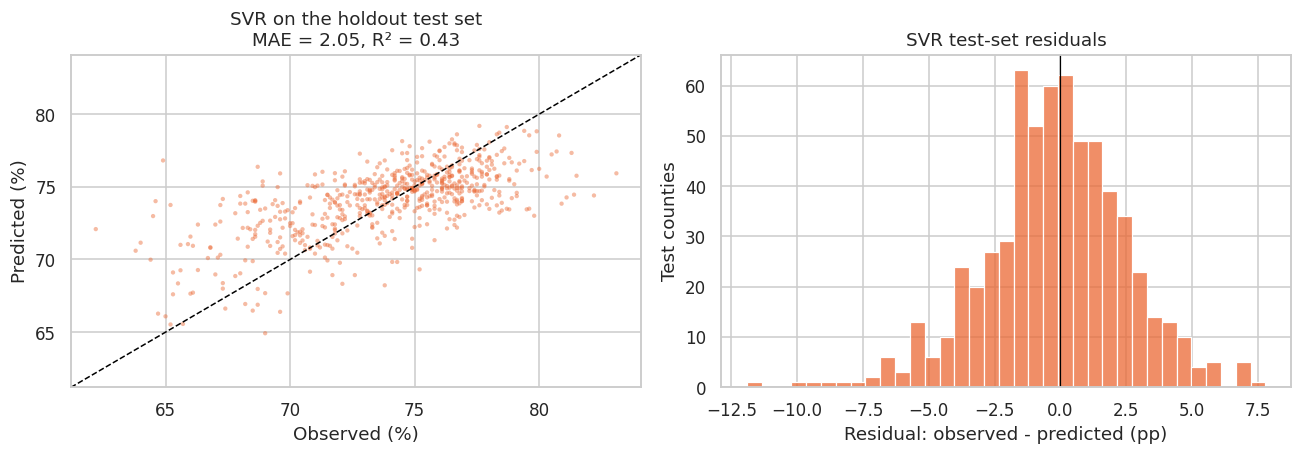

In [75]:
# bootstrap 95% interval for the selected model's test MAE and for its improvement over the baseline
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.values
err_best = np.abs(yt - test_preds[BEST_MODEL_NAME])
err_dummy = np.abs(yt - test_preds["Dummy"])
boot = rng.integers(0, len(yt), size=(2000, len(yt)))
mae_boot = err_best[boot].mean(axis=1)
gain_boot = (err_dummy[boot] - err_best[boot]).mean(axis=1)
print(f"{BEST_MODEL_NAME} test MAE {err_best.mean():.3f} (95% bootstrap CI {np.percentile(mae_boot, 2.5):.3f}-{np.percentile(mae_boot, 97.5):.3f})")
print(f"Improvement over Dummy: {gain_boot.mean():.3f} pp (95% CI {np.percentile(gain_boot, 2.5):.3f}-{np.percentile(gain_boot, 97.5):.3f})")

best_pred = test_preds[BEST_MODEL_NAME]
lims = (min(y_test.min(), best_pred.min()) - 1, max(y_test.max(), best_pred.max()) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

# predicted vs observed
axes[0].scatter(y_test, best_pred, s=8, alpha=0.45, color=MODEL_COLORS[BEST_MODEL_NAME], edgecolors="none")
axes[0].plot(lims, lims, color="black", ls="--", lw=1)
axes[0].set(xlim=lims, ylim=lims, xlabel="Observed (%)", ylabel="Predicted (%)",
            title=f"{BEST_MODEL_NAME} on the holdout test set\nMAE = {err_best.mean():.2f}, R² = {r2_score(y_test, best_pred):.2f}")

# residual distribution of the selected model
test_resid = y_test.values - best_pred
sns.histplot(test_resid, bins=35, ax=axes[1], color=MODEL_COLORS[BEST_MODEL_NAME], edgecolor="white")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(xlabel="Residual: observed - predicted (pp)", ylabel="Test counties",
            title=f"{BEST_MODEL_NAME} test-set residuals")

plt.tight_layout()
savefig("test_set_final")
plt.show()

**Holdout result.**
- The SVR achieves **test MAE 2.05 pp** (95% bootstrap CI 1.92–2.19), RMSE 2.70, and R² 0.43, a 0.77 pp (≈ 27%) improvement over the median baseline (95% CI 0.62–0.90 pp). This closely matches its random-CV MAE (2.11), and the baseline's test MAE (2.82) matches its CV value (2.81), so the test set is representative rather than unusually easy.
- Because the train/test split is random by county, this result reflects performance on new counties in states represented in training. Generalization to unseen states is weaker (state-grouped CV MAE 2.46, R² −0.16; Section 9.1).

## 11. Tradeoffs

**1. Accuracy vs. conceptual validity (SVI).**
Adding the 16 SVI indicators is the largest performance gain in the analysis: SVR MAE falls from 2.105 to ~1.62 pp under random CV (R² 0.41 → ~0.62) and by ~0.33 pp under state-grouped CV. But several of the most important SVI features (minority share, poverty, uninsured) overlap with the demographic and socioeconomic inputs PLACES uses in its small-area estimation, so part of the gain may come from partially reconstructing the target rather than from new information about access. SVI also changes the interpretation: hospitals (rank 2 → 21), primary-care physicians (4 → 24), FQHCs, and beds lose most of their importance, while density, PA, and NP supply hold up. We keep the access-only specification as the primary result because it answers the research question as posed, and report SVI as an upper bound on what community context adds.

**2. Accuracy vs. interpretability (model family).**
SVR and Gradient Boosting outperform Elastic Net by ~0.22 pp MAE (2.105 vs 2.329; R² 0.41 vs 0.30), confirming that the density and facility relationships are nonlinear. Elastic Net is much easier to explain: it reduces to a Lasso solution with a handful of nonzero coefficients that can be read directly, and it has the smallest overfitting gap and the smallest loss under state-grouped CV (+0.24 vs +0.35 pp). SVR's predictions can only be explained indirectly, through permutation importance and partial dependence. The ~10% MAE improvement justifies SVR as the selected model, but Elastic Net remains the more transparent reference for describing direction of associations.

**3. Within-state performance vs. geographic generalization.**
This is the most important limitation. The selected SVR performs well on new counties in states it has seen (random-CV MAE 2.105; holdout test MAE 2.053, R² 0.43), but when entire states are held out, MAE rises to 2.455 pp and R² becomes **negative (−0.16)**. Its predictions for an unseen state are worse, in squared-error terms, than that state's own average. MAE still beats the grouped median baseline (2.455 vs 3.056), so the model retains some ranking information, but it cannot recover a new state's overall checkup level. The holdout test result should therefore be read as within-state performance; the state-grouped results are the better guide to how the model would perform in a state outside the training data. Improving cross-state generalization would require state-level information (policy, insurance, health-system context) that is outside the access-only feature set.

## 12. Save Results

In [76]:
cv_out = pd.DataFrame(cv_rows).drop(columns="fold_MAE")
cv_out.to_csv(SUP_TABLE_DIR / "cv_results_all.csv", index=False)
sensitivity.to_csv(SUP_TABLE_DIR / "sensitivity_specifications.csv", index=False)
ablation.to_csv(SUP_TABLE_DIR / "group_ablation.csv", index=False)
perm_summary.to_csv(SUP_TABLE_DIR / "permutation_importance.csv", index=False)
by_state.to_csv(SUP_TABLE_DIR / "state_grouped_errors.csv")
segment_errors.to_csv(SUP_TABLE_DIR / "failure_segment_errors.csv")
worst.to_csv(SUP_TABLE_DIR / "failure_worst_counties.csv", index=False)
test_results.to_csv(SUP_TABLE_DIR / "test_results.csv")
skew_table.to_csv(SUP_TABLE_DIR / "eda_skew_summary.csv")
missingness.to_csv(SUP_TABLE_DIR / "eda_missingness.csv", index=False)

pd.Series({m: {k: (str(v) if not isinstance(v, (int, float, str)) else v) for k, v in p.items()}
           for m, p in best_params.items()}).to_json(SUP_TABLE_DIR / "best_params.json", indent=2)
print(sorted(p.name for p in SUP_TABLE_DIR.iterdir()))
print(sorted(p.name for p in SUP_FIG_DIR.iterdir()))

['best_params.json', 'cv_results_all.csv', 'eda_missingness.csv', 'eda_skew_summary.csv', 'failure_segment_errors.csv', 'failure_worst_counties.csv', 'group_ablation.csv', 'permutation_importance.csv', 'sensitivity_specifications.csv', 'state_grouped_errors.csv', 'test_results.csv']
['eda_binned_scatter.png', 'eda_spearman_primary.png', 'eda_target_by_group.png', 'eda_target_by_state.png', 'eda_target_distribution.png', 'eda_target_rho_all.png', 'enet_regularization_path.png', 'enet_tuning.png', 'failure_residual_vs_observed.png', 'gb_loss_curve.png', 'group_ablation.png', 'model_comparison_cv.png', 'partial_dependence_best.png', 'perm_importance_all_models.png', 'permutation_importance.png', 'permutation_importance_svi.png', 'pred_vs_obs_oof.png', 'residual_boxplots_oof.png', 'sensitivity_specs.png', 'state_bias_grouped_cv.png', 'svr_tuning.png', 'test_set_final.png']
